In [1]:
import math 
import matplotlib.pyplot as plt
import numpy as np
import random
import statistics


# Один нейрон — 2

В первой части нейрон обучен: $\hat c = 27.788\,A - 0.121$, спуск сошёлся с МНК до последнего знака, контроль пройден, обе пациентские пробы разобраны. Здесь — то, что на этих же пяти точках ещё не прожито: что один промах делает с калибровкой, чем «не доучила» отличается от «не может», и арифметика разведения пробы, которой лаборатории пользуются каждый день.

**Устройство.** Блоки 1–3 — обязательные; блоки со звёздочкой — по желанию, в любом порядке, но 5* и 8* опираются на генератор из 4*.

**Правила прежние**, плюс одно новое: блоки 1–3 — чистый Python (`math` + `matplotlib`, как в первой части); `numpy` разрешён только там, где стоит пометка.

**Справочные числа из первой части:** $w = 27.788$, $b = -0.121$, $A_0 = 0.00435$ (из 4.12*), $\eta^* = 0.173$ (из 4.5), остатки честной калибровки — до $0.05$ ммоль/л (из 4.8).

## Блок 1. Один промах и три потери

В первой части все пять калибраторов почти лежали на прямой, и вывод 4.8 был: остатки — случайный шум прибора. Настоящие данные так ведут себя не всегда. Одна испорченная точка — грязная кювета, перепутанный флакон, описка при переписывании паспорта в журнал. Что один промах делает с калибровкой — и какая функция потерь умеет ему сопротивляться.

### 1.1. Промах

При переписывании паспорта калибровочного набора в журнал для калибратора 3 записали приписанное значение соседнего флакона. Таблица получилась такой:

| Раствор | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| $c$, ммоль/л | 2.5 | 5.0 | **12.0** | 15.0 | 20.0 |
| $A$ | 0.095 | 0.183 | 0.364 | 0.546 | 0.723 |

Обучи нейрон по этой таблице — как удобнее: МНК или твой спуск из 4.5. Выведи:

- $w$ и $b$ **рядом с чистыми** ($27.788$, $-0.121$);
- остатки всех пяти калибраторов, с их знаками;
- контрольный материал ($A = 0.235$, приписано $6.25$, допуск $\pm 10\%$): прошёл? с каким запасом?
- пациентскую пробу ($A = 0.415$; честный нейрон отвечал $11.41$).

Вопросы: во что превратился свободный член и на сколько сдвинулись **все** пациентские ответы этой лаборатории? Какая доля суммы $S$ пришлась на испорченную точку?

In [2]:
#Данные
c_cal = [2.5, 5.0, 12.0, 15.0, 20.0]
A_cal = [0.095, 0.183, 0.364, 0.546, 0.723]

In [3]:
#референсные значения w и b
w_ref = 27.788
b_ref = - 0.121

In [4]:
# 1.1 — промах: веса, остатки, контроль, пациент
n = len(c_cal)

sum_A = sum(A_cal)
sum_A2 = sum(a**2 for a in A_cal)
sum_c = sum(c_cal)
sum_Ac = sum(A_cal[i] * c_cal[i] for i in range(n))
print(f"Значения sum_A = {sum_A} | sum_A2 = {sum_A2} | sum_c = {sum_c} | sum_Ac = {sum_Ac}")

D  = n * sum_A2 - sum_A * sum_A
Dw = n * sum_Ac - sum_A * sum_c
Db = sum_A2 * sum_c - sum_A * sum_Ac

#Находим w и b
w_new = Dw / D
b_new = Db / D

print(f"Точные значения новых значений w и b по МНК:")
print(f"w_new = {w_new:.3f}")
print(f"b_new = {b_new:.3f}")


Значения sum_A = 1.911 | sum_A2 = 0.995855 | sum_c = 54.5 | sum_Ac = 28.1705
Точные значения новых значений w и b по МНК:
w_new = 27.651
b_new = 0.332


In [5]:
print("Сравнение референсных значений w и b с пересчитанными по новым данным")
print(f"Референсное значение (w): {w_ref:.3f} | Новое значение (w): {w_new:.3f}")
print(f"Референсное значение (b): {b_ref:.3f} | Новое значение (b): {b_new:.3f}")
print("-" * 60)

# Абсолютная ошибка
total_err_w = abs(w_ref - w_new)
total_err_b = abs(b_ref - b_new)

# Относительная ошибка (правильная формула: |разница| / |истина| * 100%)
rel_err_w = (total_err_w / abs(w_ref)) * 100
rel_err_b = (total_err_b / abs(b_ref)) * 100

print(f"Абсолютная ошибка по w: {total_err_w:.3f} | Относительная ошибка по w: {rel_err_w:.3f}%")
print(f"Абсолютная ошибка по b: {total_err_b:.3f} | Относительная ошибка по b: {rel_err_b:.3f}%")

Сравнение референсных значений w и b с пересчитанными по новым данным
Референсное значение (w): 27.788 | Новое значение (w): 27.651
Референсное значение (b): -0.121 | Новое значение (b): 0.332
------------------------------------------------------------
Абсолютная ошибка по w: 0.137 | Относительная ошибка по w: 0.492%
Абсолютная ошибка по b: 0.453 | Относительная ошибка по b: 374.125%


In [6]:
print("Абсолюные остатки (ошибки) по каждому калибратору, ммоль/л:")
for i in range(len(A_cal)):
    # Предсказание нейрона
    c_pred = w_new * A_cal[i] + b_new
    # истина минус предсказание
    r_i = c_cal[i] - c_pred 

    print(f"Калибратор {i+1} (c = {c_cal[i]}): {r_i:.4f}")

print("-" * 60)
print(f"Относительные ошибки по каждому калибратору:")
for i in range(len(A_cal)):
    c_pred = w_new * A_cal[i] + b_new
    # истина минус предсказание
    r_i = c_cal[i] - c_pred 
    rel_error = (abs(r_i) / c_cal[i]) * 100
    print(f"Калибратор {i+1} (c = {c_cal[i]}): {rel_error:.4f}%")

Абсолюные остатки (ошибки) по каждому калибратору, ммоль/л:
Калибратор 1 (c = 2.5): -0.4586
Калибратор 2 (c = 5.0): -0.3919
Калибратор 3 (c = 12.0): 1.6033
Калибратор 4 (c = 15.0): -0.4293
Калибратор 5 (c = 20.0): -0.3235
------------------------------------------------------------
Относительные ошибки по каждому калибратору:
Калибратор 1 (c = 2.5): 18.3424%
Калибратор 2 (c = 5.0): 7.8374%
Калибратор 3 (c = 12.0): 13.3604%
Калибратор 4 (c = 15.0): 2.8618%
Калибратор 5 (c = 20.0): 1.6177%


In [7]:
#контрольный материал A = 0.235 с = 6.25
c_lab = 6.25
A_lab = 0.235

c_pred = w_new * A_lab + b_new

# Правильная относительная ошибка
rel_error_ctrl = (abs(c_pred - c_lab) / c_lab) * 100
print(f"Предсказанное значение: {c_pred:.3f} ммоль/л, относительная ошибка от контроля: {rel_error_ctrl:.2f}%")

# Проверка допуска +- 10%
tolerance = 0.10
min_value = c_lab * (1 - tolerance)
max_value = c_lab * (1 + tolerance)

if min_value <= c_pred <= max_value: 
    print(f"Значение В диапазоне допуска [{min_value:.3f}, {max_value:.3f}]")
else:
    print(f"Значение НЕ в диапазоне допуска [{min_value:.3f}, {max_value:.3f}]")

diff_up = max_value - c_pred
diff_bottom = c_pred - min_value 
print(f"Запас от верхней границы: {diff_up:.3f}, от нижней границы: {diff_bottom:.3f}")

Предсказанное значение: 6.830 ммоль/л, относительная ошибка от контроля: 9.28%
Значение В диапазоне допуска [5.625, 6.875]
Запас от верхней границы: 0.045, от нижней границы: 1.205


In [8]:
#сравнение с пациентской пробой A = 0.415 с = 11.41
A_patient = 0.415
c_patient = 11.41 

c_pred_patient = w_new * A_patient + b_new

rel_error_patient = (abs(c_pred_patient - c_patient) / c_patient) * 100

print(f"Предсказанное значение для пациента: {c_pred_patient:.3f} ммоль/л")
print(f"Честное значение было: {c_patient:.3f} ммоль/л")
print(f"Относительная ошибка предсказания: {rel_error_patient:.2f}% (сдвиг на {c_pred_patient - c_patient:+.3f} ммоль/л)")

Предсказанное значение для пациента: 11.807 ммоль/л
Честное значение было: 11.410 ммоль/л
Относительная ошибка предсказания: 3.48% (сдвиг на +0.397 ммоль/л)


In [9]:
# Значения, посчитанные по испорченной таблице (берём из 1.1, не переписываем руками)
w_corrupt, b_corrupt = w_new, b_new
# Чистые референсные значения
w_ref, b_ref = 27.788, -0.121

# Во что превратился свободный член
shift_b = b_corrupt - b_ref
print(f"Свободный член b: был {b_ref}, стал {b_corrupt:.3f} (сдвиг на {shift_b:+.3f})")

# На сколько сдвинулись пациентские ответы (на примере пробы A = 0.415)
A_patient = 0.415
c_patient = 11.41

c_pred_ref = w_ref * A_patient + b_ref
c_pred_corrupt = w_corrupt * A_patient + b_corrupt
shift_patient = c_pred_corrupt - c_pred_ref
print(f"Ответ для пациента (A={A_patient}): был {c_pred_ref:.2f}, стал {c_pred_corrupt:.2f} (сдвиг на {shift_patient:+.2f} ммоль/л)")


Свободный член b: был -0.121, стал 0.332 (сдвиг на +0.453)
Ответ для пациента (A=0.415): был 11.41, стал 11.81 (сдвиг на +0.40 ммоль/л)


In [10]:
error_sq = []
for i in range(len(A_cal)):
    r_i = c_cal[i] - (w_new * A_cal[i] + b_new) 
    r_i_sq = r_i**2
    error_sq.append(r_i_sq)

S_total = sum(error_sq)
print(f"Общая сумма квадратов ошибок S = {S_total:.4f}")

spoiled_idx = 2 #Индекс испорченной точки
share_spoiled = (error_sq[spoiled_idx] / S_total) * 100
print(f"Вклад испорченной точки в общую ошибку S: {share_spoiled:.2f}%")

# Что было бы с этой точкой при референсных весах
r_3_clean = c_cal[spoiled_idx] - (w_ref * A_cal[spoiled_idx] + b_ref)
print(f"При 'честных' весах ({w_ref}, {b_ref}) остаток 3-й точки был бы {r_3_clean:+.4f} (r² = {r_3_clean**2:.4f})")


Общая сумма квадратов ошибок S = 3.2232
Вклад испорченной точки в общую ошибку S: 79.75%
При 'честных' весах (27.788, -0.121) остаток 3-й точки был бы +2.0062 (r² = 4.0247)


**Ответ 1.1 (что сделал один промах).**
1. Значение свободного члена (b) сменилось с -0.121 на 0.332. Это изменение повлекло за собой и изменения значений всей калибровочной кривой.

2. Из-за этого подъема все результаты анализа пациентских проб систематически завысились: При A=0.415 результат был 11.41 ммоль/л, стал 11.81 ммоль/л (сдвиг на +0.40 ммоль/л). 

3. На одну испорченную точку пришлось около 79.75% от всей суммы квадратов ошибок S.

### 1.2. Кто кого тащит: вклады и Хубер

Вклад точки в $S$ — это её $r_i^2$. Посчитай вклады пяти точек при подгонке из 1.1 и покажи их столбчатым графиком (`bar`). Остальные четыре точки для сравнения — на одном графике.

Теперь потеря Хубера: вместо $r^2$ — функция, которая при $|r| \le \delta$ ведёт себя как $r^2/2$, а при $|r| > \delta$ — как модуль, $\delta(|r| - \delta/2)$. Маленькие остатки штрафуются по-прежнему мягко, а голос большого перестаёт расти: у производной есть потолок $\delta$.

Минимизируется она итерациями — механика знакома тебе по алгоритму Вайсфельда:

1. МНК → остатки $r_i$;
2. веса: $1$ при $|r_i| \le \delta$, иначе $\delta / |r_i|$;
3. взвешенный МНК (суммы с весами — система 2×2 решается твоим же Крамером);
4. снова остатки — и так до сходимости.

Возьми $\delta = 0.1$ и прогони. Выведи $w$, $b$ рядом с чистыми и **веса всех пяти точек** в финальной итерации. Какой вес получил брак — и что это значит словами («голос этой точки урезали в столько-то раз»)?

Сумма квадратов S = 3.2232
Точка 1: r = -0.4586, r² = 0.2103, доля = 6.52%
Точка 2: r = -0.3919, r² = 0.1536, доля = 4.76%
Точка 3: r = +1.6033, r² = 2.5704, доля = 79.75%
Точка 4: r = -0.4293, r² = 0.1843, доля = 5.72%
Точка 5: r = -0.3235, r² = 0.1047, доля = 3.25%


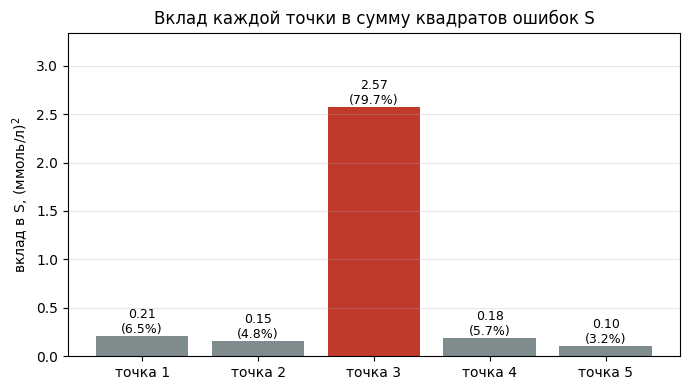

In [11]:
# 1.2 — вклады точек в S и Хубер с delta = 0.1 итерациями

# --- вклады точек в S при подгонке из 1.1 ---
w_fit, b_fit = w_new, b_new          # МНК по испорченной таблице (ячейка 1.1)
OUTLIER = 3                          # номер испорченного калибратора

err_points = []
for i in range(len(A_cal)):
    c_pred = w_fit * A_cal[i] + b_fit
    # истина минус предсказание
    r_i = c_cal[i] - c_pred
    r_sqr = r_i ** 2
    err_points.append(r_sqr)

S = sum(err_points)
print(f"Сумма квадратов S = {S:.4f}")
for i in range(len(err_points)):
    r_i = c_cal[i] - (w_fit * A_cal[i] + b_fit)
    print(f"Точка {i + 1}: r = {r_i:+.4f}, r² = {err_points[i]:.4f}, "
          f"доля = {err_points[i] / S * 100:.2f}%")

# --- столбчатый график: вклад каждой точки в S ---
num = list(range(1, len(err_points) + 1))
colors = ["#c0392b" if i == OUTLIER else "#7f8c8d" for i in num]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(num, err_points, color=colors)
ax.set_xticks(num)
ax.set_xticklabels([f"точка {i}" for i in num])
ax.set_ylabel("вклад в S, (ммоль/л)$^2$")
ax.set_title("Вклад каждой точки в сумму квадратов ошибок S")
ax.grid(axis="y", alpha=0.3)

for bar, e in zip(bars, err_points):
    ax.annotate(f"{e:.2f}\n({e / S * 100:.1f}%)",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, max(err_points) * 1.30)

plt.tight_layout()
plt.show()


In [12]:
# 1.2 (продолжение) — Хубер: IRLS-функция

def rho_huber(r, delta):
    if abs(r) <= delta:
        return 0.5 * r * r
    return delta * (abs(r) - delta / 2)

def psi_huber(r, delta):
    if abs(r) <= delta:
        return r
    return delta if r > 0 else -delta


def fit_huber(c, A, delta=0.1, eps=1e-10, max_iter=100, verbose=False):
    """Подгонка прямой c = w*A + b с потерями Хубера (IRLS).

    c, A          — списки измерений одинаковой длины;
    delta         — порог «шум/брак», в единицах c;
    eps           — порог по сдвигу w и b (проверяются раздельно);
    max_iter      — предел итераций;
    verbose       — печатать таблицу итераций.

    Возвращает dict: w, b, residuals, weights, S, psi_sum, psi_sum_A,
    iterations, converged, history.
    """
    n = len(c)

    # старт — обычный МНК по тем же точкам
    sA  = sum(A)
    sA2 = sum(a * a for a in A)
    sc  = sum(c)
    sAc = sum(A[i] * c[i] for i in range(n))
    D0  = n * sA2 - sA * sA
    w = (n * sAc - sA * sc) / D0
    b = (sA2 * sc - sA * sAc) / D0

    history = []
    converged = False

    for iteration in range(1, max_iter + 1):
        residual = [c[i] - (w * A[i] + b) for i in range(n)]
        weights = [1.0 if abs(r) <= delta else delta / abs(r) for r in residual]

        sw   = sum(weights)
        swA  = sum(weights[i] * A[i] for i in range(n))
        swc  = sum(weights[i] * c[i] for i in range(n))
        swA2 = sum(weights[i] * A[i] ** 2 for i in range(n))
        swAc = sum(weights[i] * A[i] * c[i] for i in range(n))

        D = sw * swA2 - swA ** 2
        w_next = (sw * swAc - swA * swc) / D
        b_next = (swA2 * swc - swA * swAc) / D

        residual_next = [c[i] - (w_next * A[i] + b_next) for i in range(n)]
        weights_next = [1.0 if abs(r) <= delta else delta / abs(r) for r in residual_next]
        S = sum(rho_huber(r, delta) for r in residual_next)
        step = max(abs(w_next - w), abs(b_next - b))
        max_dw = max(abs(weights_next[i] - weights[i]) for i in range(n))

        history.append({
            "iteration": iteration,
            "w": w_next,
            "b": b_next,
            "S": S,
            "step": step,
            "max_dw": max_dw,
            "weights": weights_next,
        })

        # критерий останова — по параметрам, до перезаписи
        converged = abs(w_next - w) < eps and abs(b_next - b) < eps
        w, b = w_next, b_next
        if converged:
            break

    residual = [c[i] - (w * A[i] + b) for i in range(n)]
    weights = [1.0 if abs(r) <= delta else delta / abs(r) for r in residual]
    S = sum(rho_huber(r, delta) for r in residual)

    if verbose:
        print(f"{'итер':>4} {'w':>12} {'b':>11} {'S_Huber':>12} {'шаг':>9} {'max|dW|':>9}")
        prev_S = None
        for h in history:
            flag = "" if prev_S is None or h["S"] <= prev_S + 1e-12 else "  <-- S выросла!"
            prev_S = h["S"]
            print(f"{h['iteration']:>4} {h['w']:>12.8f} {h['b']:>+11.8f} {h['S']:>12.9f} "
                  f"{h['step']:>9.2e} {h['max_dw']:>9.2e}{flag}")

    return {
        "w": w,
        "b": b,
        "residuals": residual,
        "weights": weights,
        "S": S,
        "psi_sum": sum(psi_huber(r, delta) for r in residual),
        "psi_sum_A": sum(psi_huber(residual[i], delta) * A[i] for i in range(n)),
        "iterations": iteration,
        "converged": converged,
        "history": history,
    }


# --- прогон на калибровочных данных из 1.1 ---
res = fit_huber(c_cal, A_cal, delta=0.1, verbose=True)

print(f"\nОстановка: {res['iterations']} итераций, w = {res['w']:.9f}, b = {res['b']:.9f}, сошлось = {res['converged']}")

print("\nВеса в финальной итерации:")
for i in range(n):
    print(f"  точка {i + 1}: r = {res['residuals'][i]:+.4f}, вес = {res['weights'][i]:.4f}")

print("\nПроверка оптимальности (должны быть ~0):")
print(f"  sum psi     = {res['psi_sum']:+.3e}")
print(f"  sum psi * A = {res['psi_sum_A']:+.3e}")

print(f"\nХубер:  w = {res['w']:.3f}, b = {res['b']:+.3f}")
print(f"Чистые: w = {w_ref:.3f}, b = {b_ref:+.3f} (сдвиг b на {res['b'] - b_ref:+.3f})")


итер            w           b      S_Huber       шаг   max|dW|
   1  27.71459320 +0.02740305  0.212468246  3.04e-01  7.45e-01
   2  27.77396573 -0.07642258  0.197512633  1.04e-01  3.76e-01
   3  27.78021131 -0.09380467  0.197047858  1.74e-02  3.88e-04
   4  27.78027641 -0.09401949  0.197047783  2.15e-04  4.87e-06
   5  27.78027723 -0.09402219  0.197047783  2.70e-06  6.11e-08
   6  27.78027724 -0.09402222  0.197047783  3.39e-08  7.67e-10
   7  27.78027724 -0.09402222  0.197047783  4.25e-10  9.62e-12
   8  27.78027724 -0.09402222  0.197047783  5.34e-12  1.21e-13

Остановка: 8 итераций, w = 27.780277243, b = -0.094022224, сошлось = True

Веса в финальной итерации:
  точка 1: r = -0.0451, вес = 1.0000
  точка 2: r = +0.0102, вес = 1.0000
  точка 3: r = +1.9820, вес = 0.0505
  точка 4: r = -0.0740, вес = 1.0000
  точка 5: r = +0.0089, вес = 1.0000

Проверка оптимальности (должны быть ~0):
  sum psi     = -2.235e-13
  sum psi * A = -7.909e-14

Хубер:  w = 27.780, b = -0.094
Чистые: w = 27.78

**Ответ 1.2 (вклад брака в S; что сделал Хубер).**
Вклад испорченной точки (3-й калибратор, c = 12.0) в общую сумму квадратов ошибок S составил около 79.7%

Хубер с delta=0.1 решил проблему: вес брака(точка 3) упал до 0.0505, его вклад в обшую ошибку снизился. Четыре нормальные точки получили вес 1.0, их не тронули. Итоговые параметры w=27.780, b=-0.094 почти вернулись к «чистым» (27.788, -0.121). 

### 1.3*. $\delta$ — порог «шум или брак»

Прогони 1.2 для $\delta$ из $\{0.5,\ 0.2,\ 0.1,\ 0.05,\ 0.02,\ 0.01\}$. Таблица: $\delta$, $w$, $b$, вес калибратора 3, вес самого «нормального» калибратора.

Где прямая перестаёт замечать брак? Где $\delta$ становится меньше шума прибора (~$0.05$ ммоль/л из 4.8) — и что тогда происходит с весами честных точек? Как выбрала бы $\delta$ по гистограмме остатков честной калибровки из 4.8?

$\delta$ — это твой первый гиперпараметр: число, которое задаёшь не обучением, а решением. Здесь у него есть физический смысл — «остаток больше стольких-то ммоль/л я считаю браком, а не шумом».

In [13]:
# 1.3* — сетка delta: все веса точек
for d in [0.5, 0.2, 0.1, 0.05, 0.02, 0.01]:
    r = fit_huber(c_cal, A_cal, delta=d)
    weights = [f"{w:.3f}" for w in r['weights']]
    print(f"delta={d}: w={r['w']:.3f}, b={r['b']:+.3f}, веса=[{', '.join(weights)}]")

delta=0.5: w=27.746, b=+0.019, веса=[1.000, 1.000, 0.266, 1.000, 1.000]
delta=0.2: w=27.772, b=-0.066, веса=[1.000, 1.000, 0.102, 1.000, 1.000]
delta=0.1: w=27.780, b=-0.094, веса=[1.000, 1.000, 0.050, 1.000, 1.000]
delta=0.05: w=27.796, b=-0.108, веса=[1.000, 1.000, 0.025, 0.729, 1.000]
delta=0.02: w=27.802, b=-0.104, веса=[0.542, 1.000, 0.010, 0.265, 1.000]
delta=0.01: w=27.790, b=-0.094, веса=[0.216, 1.000, 0.005, 0.126, 1.000]


**Вывод:** прямая перестаёт замечать брак уже при delta = 0.1, вес испорченной 3-й точки падает до 0.0505, параметры модели практически возвращаются к «чистым» референсным значениям (27.788 и -0.121). 

Если брать маленькое значение delta (например, 0.02 или 0.01
0.01), становится меньше естественных колебаний нормальных точек. В результате веса «честных» калибраторов начинают падать ниже 1.0, что ухудшает точность модели.

По гистограмме остатков нужно выбирать delta чуть больше максимального ожидаемого шума, в такое случае нормальные точки не страдают, а аномальные выбросы получают меньшее влияние на ошибку. 

## Блок 2. Недообучение: две разные болезни

«Нейрон обучен плохо» — это два разных диагноза. **«Не дошёл»**: спуск ещё в пути, параметры не добрались до дна чаши. **«Не может»**: модель в принципе не способна описать данные. Лечения противоположны по цене: в первом случае — ещё немного итераций, во втором — другая модель, и никакие итерации не помогут. Различаются они по кривой обучения и по остаткам.

### 2.1. «Не дошёл»

Возьми свой спуск из 4.5 (старт $w=0$, $b=0$, $\eta = 0.1$) и останови его на **10-й итерации**. Выведи:

- $w$, $b$ и $S$ в этой точке (и $S$ в минимуме — для сравнения);
- остатки пяти калибраторов с их знаками;
- кривую обучения с отмеченной точкой остановки.

Вопросы: остатки случайны или выстроены? Упала ли $S$ до дна? Что делать — учить дальше или менять модель? Проверь ответ делом: доведи спуск до конца и посмотри, что стало с узором остатков.

Градиент в старте (0, 0): dS/dw = -54.8850, dS/db = -105.0000
Спуск из (0, 0):     w = 27.788367, b = -0.120714, S = 0.005217
S упала в 100 раз на итерации 32
Граница устойчивости: eta* = 2/lambda_max = 0.1734
  eta = 0.10: S после 50 итераций = 1.384e+00
  eta = 0.17: S после 50 итераций = 1.056e+01
  eta = 0.18: S после 50 итераций = 8.836e+05
  eta = 0.20: S после 50 итераций = 2.414e+14


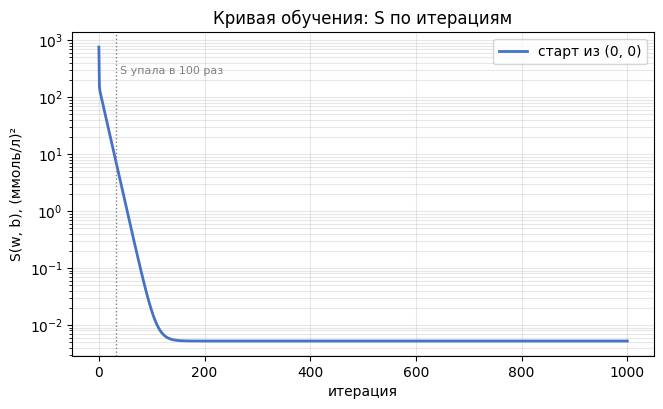

In [14]:
# 4.5 — градиентный спуск по (w, b) и кривая обучения

A_cal = [0.095, 0.183, 0.364, 0.546, 0.723]
c_cal = [2.5, 5.0, 10.0, 15.0, 20.0]

def S(w, b):
    return sum((c - (w * A + b)) ** 2 for A, c in zip(A_cal, c_cal))

# производные: 2·Σ A_i·(wA_i + b - c_i) и 2·Σ (wA_i + b - c_i)
# (это те же формулы из 4.4, только знак вынесен так, чтобы был плюс)
def dS_dw(w, b):
    return 2 * sum(A * (w * A + b - c) for A, c in zip(A_cal, c_cal))

def dS_db(w, b):
    return 2 * sum(w * A + b - c for A, c in zip(A_cal, c_cal))

def descent(w0, b0, eta=0.1, iters=1000):
    w, b = w0, b0
    history = [S(w, b)]
    for _ in range(iters):
        dw = dS_dw(w, b)          # обе производные считаем до обновления
        db = dS_db(w, b)
        w = w - eta * dw          # и только потом обновляем обе координаты
        b = b - eta * db
        history.append(S(w, b))
    return w, b, history

print(f"Градиент в старте (0, 0): dS/dw = {dS_dw(0, 0):.4f}, dS/db = {dS_db(0, 0):.4f}")

w_gd, b_gd, hist = descent(0.0, 0.0)
n100 = next(i for i, s in enumerate(hist) if s <= hist[0] / 100)
print(f"Спуск из (0, 0):     w = {w_gd:.6f}, b = {b_gd:.6f}, S = {hist[-1]:.6f}")
print(f"S упала в 100 раз на итерации {n100}")


# граница устойчивости: шаг обязан быть меньше 2/λmax матрицы Гессе
from math import sqrt
a2 = sum(A ** 2 for A in A_cal)
a1 = sum(A_cal)
n = len(A_cal)
lam_max = (a2 + n) + sqrt((a2 - n) ** 2 + 4 * a1 ** 2)
print(f"Граница устойчивости: eta* = 2/lambda_max = {2 / lam_max:.4f}")
for eta in (0.1, 0.17, 0.18, 0.20):
    _, _, h = descent(0.0, 0.0, eta=eta, iters=50)
    print(f"  eta = {eta:.2f}: S после 50 итераций = {h[-1]:.3e}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.semilogy(hist, color='#4472c4', lw=2, label='старт из (0, 0)')
ax.axvline(n100, color='gray', ls=':', lw=1)
ax.text(n100 + 8, hist[0] / 3, 'S упала в 100 раз', fontsize=8, color='gray')
ax.set_xlabel('итерация')
ax.set_ylabel('S(w, b), (ммоль/л)²')
ax.set_title('Кривая обучения: S по итерациям')
ax.grid(alpha=0.3, which='both')
ax.legend()
plt.show()


10 итераций: w = 12.8173, b = 5.8774, S = 59.8869
минимум:     w = 27.7884, b = -0.1207, S = 0.005217
S выше дна в 11479 раз

Остатки на 10-й итерации (c − ĉ):
  калибратор 1 (A = 0.095): -4.5950
  калибратор 2 (A = 0.183): -3.2230
  калибратор 3 (A = 0.364): -0.5429
  калибратор 4 (A = 0.546): +2.1243
  калибратор 5 (A = 0.723): +4.8557


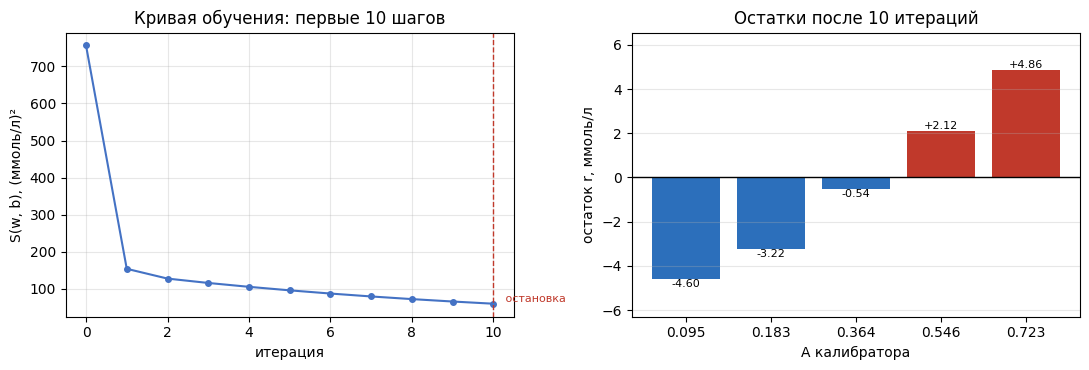

In [15]:
# 2.1 — тот же спуск, остановленный на 10-й итерации

def descent_trace(w0, b0, eta=0.1, iters=10):
    w, b = w0, b0
    trace = [(w, b, S(w, b))]
    for _ in range(iters):
        dw = dS_dw(w, b)
        db = dS_db(w, b)
        w = w - eta * dw
        b = b - eta * db
        trace.append((w, b, S(w, b)))
    return trace

trace10 = descent_trace(0.0, 0.0, eta=0.1, iters=10)
w10, b10, S10 = trace10[-1]

S_min = hist[-1]
print(f"10 итераций: w = {w10:.4f}, b = {b10:.4f}, S = {S10:.4f}")
print(f"минимум:     w = {w_gd:.4f}, b = {b_gd:.4f}, S = {S_min:.6f}")
print(f"S выше дна в {S10 / S_min:.0f} раз")

print("\nОстатки на 10-й итерации (c − ĉ):")
r10 = []
for i in range(len(A_cal)):
    r10.append(c_cal[i] - (w10 * A_cal[i] + b10))
    print(f"  калибратор {i + 1} (A = {A_cal[i]:.3f}): {r10[i]:+.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

iters = list(range(len(trace10)))
ax1.plot(iters, [t[2] for t in trace10], 'o-', color='#4472c4', lw=1.5, ms=4)
ax1.axvline(10, color='#c0392b', ls='--', lw=1)
ax1.text(10.2, S10, ' остановка', color='#c0392b', fontsize=8, va='bottom')
ax1.set_xlabel('итерация')
ax1.set_ylabel('S(w, b), (ммоль/л)²')
ax1.set_title('Кривая обучения: первые 10 шагов')
ax1.grid(alpha=0.3)

colors = ['#c0392b' if r > 0 else '#2c6fbb' for r in r10]
ax2.axhline(0, color='black', lw=1)
ax2.bar(range(1, len(r10) + 1), r10, color=colors)
ax2.set_xticks(range(1, len(r10) + 1))
ax2.set_xticklabels([f'{a:.3f}' for a in A_cal])
ax2.set_xlabel('A калибратора')
ax2.set_ylabel('остаток r, ммоль/л')
ax2.set_title('Остатки после 10 итераций')
ax2.grid(axis='y', alpha=0.3)
ax2.margins(y=0.18)
for i, r in enumerate(r10):
    ax2.annotate(f'{r:+.2f}', (i + 1, r), ha='center',
                 va='bottom' if r > 0 else 'top', fontsize=8)

plt.tight_layout()
plt.show()


**Ответ 2.1 (диагноз и проверка).** Остатки на 10-й итерации не случайны, они выстроены в закономерность. S до дна не дошла потому что градиентный спуск прервали слишком рано.

Выход - учить дальше (продолжать итерации). Если довести спуск до конца, S дойдет до дна, остатки станут маленькими и их знаки перемешаются, превратившись в случайный шум прибора (демонстрировалость в 4.8 ). 

### 2.2. «Не может»: прибор с кривизной

Тот же анализатор после года эксплуатации. Статья из Блока 1 предупреждала: при больших концентрациях наблюдаются отклонения от закона Бера. Новый протокол калибровки — те же концентрации, новые плотности:

| Раствор | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| $c$, ммоль/л | 2.5 | 5.0 | 10.0 | 15.0 | 20.0 |
| $A$ | 0.095 | 0.185 | 0.360 | 0.527 | 0.692 |

Контрольный материал на этом приборе даёт $A = 0.227$ (приписано $6.25$, допуск $\pm 10\%$).

Обучи линейный нейрон **полностью** — проверь, что спуск дошёл до дна. Затем:

- остатки пяти калибраторов с их знаками — выстроены или вперемешку?
- scatter-график точек: видно ли кривизну глазом?
- контроль: прошёл?

Центральный вопрос: чем этот случай отличается от 2.1 — и почему здесь **больше итераций не поможет**? Контроль молчит — тогда откуда лаборатории знать, что модель «не может»? Дополнительная: пациентская проба на этом приборе даёт $A = 0.405$; что ответит твой нейрон и насколько это далеко от честных $11.41$? Почему так близко, если модель не может?

Спуск из (0, 0): w = 29.328467, b = -0.404324, S = 0.052672

Остатки по каждому калибратору (истина - предсказание):
  Калибратор 1 (c=  2.5, A=0.095): остаток = +0.1181
  Калибратор 2 (c=  5.0, A=0.185): остаток = -0.0214
  Калибратор 3 (c= 10.0, A=0.360): остаток = -0.1539
  Калибратор 4 (c= 15.0, A=0.527): остаток = -0.0518
  Калибратор 5 (c= 20.0, A=0.692): остаток = +0.1090


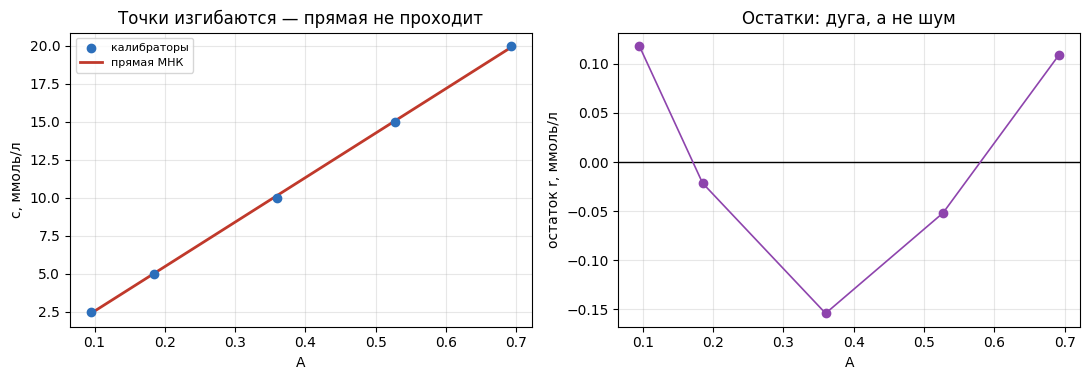

In [16]:
# 2.2 — кривые данные: полная сходимость, остатки, контроль
A_new = [0.095, 0.185, 0.360, 0.527, 0.692]
c_new = [2.5, 5.0, 10.0, 15.0, 20.0]

# свои имена: не затираем функции из 4.5 и 2.1 — они нужны дальше, в блоке 3
def S2(w, b):
    return sum((c - (w * A + b)) ** 2 for A, c in zip(A_new, c_new))

def dS_dw2(w, b):
    return 2 * sum(A * (w * A + b - c) for A, c in zip(A_new, c_new))

def dS_db2(w, b):
    return 2 * sum(w * A + b - c for A, c in zip(A_new, c_new))

def descent2(w0, b0, eta=0.1, iters=1000):
    w, b = w0, b0
    history = [S2(w, b)]
    for _ in range(iters):
        dw = dS_dw2(w, b)
        db = dS_db2(w, b)
        w = w - eta * dw
        b = b - eta * db
        history.append(S2(w, b))
    return w, b, history

w_gd2, b_gd2, hist2 = descent2(0.0, 0.0, eta=0.1, iters=1000)
print(f"Спуск из (0, 0): w = {w_gd2:.6f}, b = {b_gd2:.6f}, S = {hist2[-1]:.6f}")

print("\nОстатки по каждому калибратору (истина - предсказание):")
residuals = []
for i in range(len(A_new)):
    c_pred = w_gd2 * A_new[i] + b_gd2
    r_i = c_new[i] - c_pred
    residuals.append(r_i)
    print(f"  Калибратор {i+1} (c={c_new[i]:>5}, A={A_new[i]:.3f}): остаток = {r_i:+.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.9))

ax1.scatter(A_new, c_new, color='#2c6fbb', zorder=3, label='калибраторы')
xx = [min(A_new), max(A_new)]
ax1.plot(xx, [w_gd2 * a + b_gd2 for a in xx], color='#c0392b', lw=2, label='прямая МНК')
ax1.set_xlabel('A')
ax1.set_ylabel('c, ммоль/л')
ax1.set_title('Точки изгибаются — прямая не проходит')
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8)

ax2.axhline(0, color='black', lw=1)
ax2.plot(A_new, residuals, 'o-', color='#8e44ad', lw=1.2)
ax2.set_xlabel('A')
ax2.set_ylabel('остаток r, ммоль/л')
ax2.set_title('Остатки: дуга, а не шум')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [17]:
A_ctrl = 0.227
c_ctrl = 6.25

c_pred_ctrl = w_gd2 * A_ctrl + b_gd2
print(f"Концентрация: {c_pred_ctrl:.4f} ммоль/л (приписано {c_ctrl})")
print(f"Относительная ошибка: {abs(c_pred_ctrl - c_ctrl) / c_ctrl * 100:.2f}%")

tolerance = 0.10
min_value = c_ctrl * (1 - tolerance)
max_value = c_ctrl * (1 + tolerance)

if min_value <= c_pred_ctrl <= max_value:
    print(f"Значение в диапазоне допуска [{min_value:.4f}, {max_value:.4f}]")
else:
    print(f"Значение не в диапазоне допуска [{min_value:.4f}, {max_value:.4f}]")

print(f"Запас до верхней границы: {max_value - c_pred_ctrl:.4f}, до нижней: {c_pred_ctrl - min_value:.4f}")


Концентрация: 6.2532 ммоль/л (приписано 6.25)
Относительная ошибка: 0.05%
Значение в диапазоне допуска [5.6250, 6.8750]
Запас до верхней границы: 0.6218, до нижней: 0.6282


In [18]:
A_patient = 0.405
c_true = 11.41

c_patient = w_gd2 * A_patient + b_gd2
print(f"Нейрон по прибору: {c_patient:.4f} ммоль/л")
print(f"Честное значение:  {c_true} ммоль/л")
print(f"Ошибка: {c_patient - c_true:+.4f} ммоль/л ({(c_patient - c_true) / c_true * 100:+.2f}%)")


Нейрон по прибору: 11.4737 ммоль/л
Честное значение:  11.41 ммоль/л
Ошибка: +0.0637 ммоль/л (+0.56%)


**Ответ 2.2 (диагноз; что видят остатки, чего не видит допуск).**
1. Нет, на графике не различить кривизну "на глаз". 
2. Контроль прошел в допуск +-10%
3. В 2.1 модель «не дошла» до дна (ошибка S была большой), потому что обучение остановили раньше чем она смогла дойти. В 2.2 спуск дошёл до самого дна (S == 0.053). Но модель всё равно ошибается. Это значит, что нужна другая модель.
4. Контроль молчит, потому что он проверяет одну точку с допуском (+- 10%), который значительно больше систематической ошибки модели. О том, что модель «не может», свидетельствует узор остатков всех калибраторов: если знаки выстроились в дугу (+,−,−,−,+), а не в случайное облако, значит линейная форма не описывает данные. 
5. По предсказанию с - 11.47 ммоль/л, что близко к честному значению.Проба A=0.405 находится внутри калибровочного интервала (между 3-м и 4-м калибраторами), следовательно на данном участке зависимость близка к линейной, ошибка небольшая.

### 2.3*. Диагностика вслепую

Три лаборатории прислали протоколы калибровки. В каждом — значение $S$ в конце (и стартовое $756$ у всех) и остатки по калибраторам:

| | $S$ в конце | остатки, ммоль/л |
|---|---|---|
| Лаборатория А | $59.9$ | $-4.6,\ -3.2,\ -0.5,\ +2.1,\ +4.9$ |
| Лаборатория Б | $0.05$ | $+0.12,\ -0.02,\ -0.15,\ -0.05,\ +0.11$ |
| Лаборатория В | $0.52$ | $-0.08,\ -0.03,\ +0.45,\ -0.52,\ +0.18$ |

Двух из них ты уже видела в этом блоке — узнай. Третью опиши как новую: что с прибором или моделью, и что делать? По какому признаку ты отделила «не дошёл» от «не может» — по остаткам или по кривой обучения? Сформулируй правило в одну фразу.

Лаборатория А - это случай 2.1 («не дошёл»). Спуск остановили слишком рано (10 итераций). Успешно сходится если продолжть обучение.

Лаборатория Б — это случай 2.2 («не может»). Спуск дошёл до дна, но остатки выстроены в характерную дугу. Модель в принципе не способна описать кривизну прибора, нужно менять модель.

Лаборатория В —  Вероятно в выборке были ошибочные/аномальные случаи как в ситуации из Блока 1.1. Причина - в распределении остатков нет закономерности, но остатки 3 и 4 (+0.45 и -0.52) заметно выбиваются по величине. Можно применить функцию Хубера из 1.2, чтобы автоматически урезать вес выброса.

**Ответ 2.3* (правило диагностики одной фразой).** Величина S говорит, дошёл ли спуск до дна. По узору остатков можно понять в чем проблема и как ее решать: монотонный тренд при большом S - нужно учить дальше, дуга при малом S - стоит сменить модель, резкие выбросы и отсутствие закономерности в остатках - есть испорченная проба.

## Блок 3. Разведение пробы: лабораторная арифметика

Из 4.10: проба 2, $A = 0.950$, — выше верхнего калибратора ($0.723$). Нейрон молча ответил $26.3$ ммоль/л. Формула безотказна и ответит всегда — но за пределами калибраторов ей верить нельзя, и лаборатория не экстраполирует, а разводит пробу, перемеряет и пересчитывает. Здесь это делается числами.

### 3.1. Вылет

Посчитай $\hat c$ для $A = 0.950$. Построй ось $A$ (от 0 до 1.0) с отметками: калибраторы, контроль, обе пациентские пробы — и покажи, где проба 2 оказалась относительно рабочего диапазона. Насколько процентов она вышла за верхнюю границу — по $A$ и по $c$?

ĉ(A = 0.95) = 26.278 ммоль/л; верхний калибратор — 20 ммоль/л
Вылет по A: +31.4% (0.723 -> 0.950)
Вылет по c: +31.4% (20 -> 26.28)


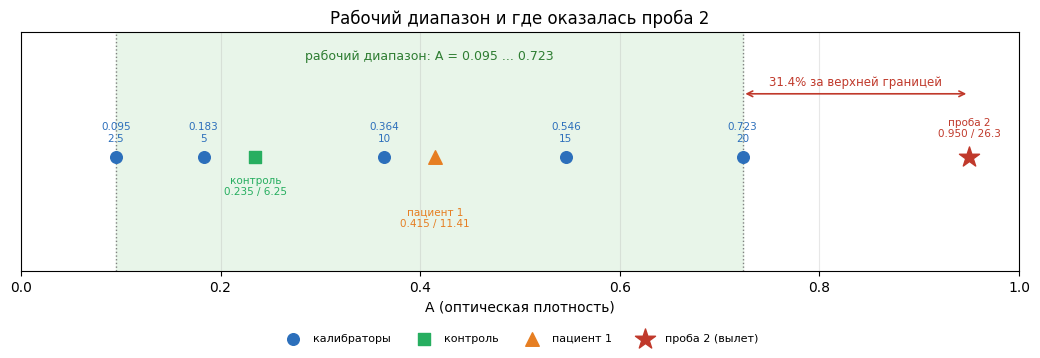

In [19]:
# 3.1 — вылет за шкалу: число и картинка
A_probe2 = 0.950
c_probe2 = w_gd * A_probe2 + b_gd

A_min_cal, A_max_cal = min(A_cal), max(A_cal)
c_max_cal = max(c_cal)

print(f"ĉ(A = {A_probe2}) = {c_probe2:.3f} ммоль/л; верхний калибратор — {c_max_cal:g} ммоль/л")
print(f"Вылет по A: {(A_probe2 - A_max_cal) / A_max_cal * 100:+.1f}% "
      f"({A_max_cal:.3f} -> {A_probe2:.3f})")
print(f"Вылет по c: {(c_probe2 - c_max_cal) / c_max_cal * 100:+.1f}% "
      f"({c_max_cal:g} -> {c_probe2:.2f})")

fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.axvspan(A_min_cal, A_max_cal, color='#e8f5e9', zorder=0)

# калибраторы
ax.scatter(A_cal, [0] * len(A_cal), s=70, color='#2c6fbb', zorder=3, label='калибраторы')
for a, cc in zip(A_cal, c_cal):
    ax.annotate(f'{a:.3f}\n{cc:g}', (a, 0.06), ha='center', va='bottom',
                fontsize=7.5, color='#2c6fbb')

# контроль
ax.scatter([0.235], [0], marker='s', s=80, color='#27ae60', zorder=3, label='контроль')
ax.annotate('контроль\n0.235 / 6.25', (0.235, -0.08), ha='center', va='top',
            fontsize=7.5, color='#27ae60')

# пациент 1
ax.scatter([0.415], [0], marker='^', s=95, color='#e67e22', zorder=3, label='пациент 1')
ax.annotate('пациент 1\n0.415 / 11.41', (0.415, -0.22), ha='center', va='top',
            fontsize=7.5, color='#e67e22')

# проба 2
ax.scatter([A_probe2], [0], marker='*', s=230, color='#c0392b', zorder=3, label='проба 2 (вылет)')
ax.annotate(f'проба 2\n0.950 / {c_probe2:.1f}', (A_probe2, 0.08), ha='center', va='bottom',
            fontsize=7.5, color='#c0392b')

# границы рабочего диапазона
for x in (A_min_cal, A_max_cal):
    ax.axvline(x, color='gray', ls=':', lw=1)
ax.annotate(f'рабочий диапазон: A = {A_min_cal:.3f} ... {A_max_cal:.3f}',
            ((A_min_cal + A_max_cal) / 2, 0.43), ha='center', fontsize=9, color='#2e7d32')

# стрелка вылета
ax.annotate('', xy=(A_probe2, 0.28), xytext=(A_max_cal, 0.28),
            arrowprops=dict(arrowstyle='<->', color='#c0392b', lw=1.2))
ax.text((A_max_cal + A_probe2) / 2, 0.315, f'{(A_probe2 - A_max_cal) / A_max_cal * 100:.1f}% за верхней границей',
        ha='center', fontsize=8.5, color='#c0392b')

ax.set_xlim(0, 1.0)
ax.set_ylim(-0.5, 0.55)
ax.set_yticks([])
ax.set_xlabel('A (оптическая плотность)')
ax.set_title('Рабочий диапазон и где оказалась проба 2')
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


**Ответ 3.1 (насколько велика экскурсия):** Проба 2 оказалась правее верхнего значения рабочего диапазона (правее по оси А). При этом нейрон выдаёт с = 26,3 ммоль/л, продолжив линейную зависимость вне рабочего диапазона.


### 3.2. Ряд разведений

Разведение: к одной части пробы добавляют $D-1$ частей воды и перемеряют. Вода поглощает наравне с пробой — **холостая не разводится**, и честная формула для перемеренной плотности не $A/D$:

$$A' = \frac{A}{D} + A_0\Bigl(1 - \frac{1}{D}\Bigr).$$

Проверь формулу на предельном случае $D = 1$ — сходится ли она к самому $A$? Выведи её сама из $A = A_0 + k\,c$ (подсказка: концентрация стала $c/D$, а холостая осталась).

Лабораторные разведения дискретны — это равные объёмы из одной пипетки: $D \in \{2, 3, 5, 10\}$. Для каждого посчитай $A'$ и $\hat c' = w A' + b$. Таблица: $D$, $A'$, между какими калибраторами оно оказалось, выше или ниже середины шкалы.

Выбери $D$ для пробы 2 и обоснуй: **куда** целиться (в середине? в верхней половине? почему не у самого верха и не у низа?) и почему $D = 10$ для этой пробы уже мимо.

$k*c = A-A0$

$A' = A0 + k*(c/D)$

$при D =1:$

$A' = A0 + A - A0 = A$

In [20]:
# 3.2 — таблица разведений и выбор D
D_list = [2, 3, 5, 10]
A_orig = 0.950

# холостая — свободный член в осях A(c): A = A0 + c/w, значит A0 = -b/w
A0 = -b_gd / w_gd
A_mid = (min(A_cal) + max(A_cal)) / 2

print(f"w = {w_gd:.6f}, b = {b_gd:.6f}, A0 = -b/w = {A0:.5f}")
print(f"середина шкалы: A = {A_mid:.3f}, c = {w_gd * A_mid + b_gd:.2f} ммоль/л\n")

# предельный случай D = 1
A_check = A_orig / 1 + A0 * (1 - 1 / 1)
print(f"Проверка D = 1: A' = {A_check:.4f} (должно быть {A_orig})\n")

print("  D       A'       c'   между калибраторами           половина")

for D in D_list:
    A_new = A_orig / D + A0 * (1 - 1 / D)
    c_new = w_gd * A_new + b_gd

    if A_new < A_cal[0]:
        where = f"ниже 1-го (< {A_cal[0]:.3f})"
    elif A_new > A_cal[-1]:
        where = f"выше 5-го (> {A_cal[-1]:.3f})"
    else:
        where = ""
        for i in range(len(A_cal) - 1):
            if A_cal[i] <= A_new <= A_cal[i + 1]:
                where = f"{i + 1}-й и {i + 2}-й: {A_cal[i]:.3f} ... {A_cal[i + 1]:.3f}"
                break

    half = "выше середины" if A_new > A_mid else "ниже середины"
    print(f"{D:>3}  {A_new:>7.4f}  {c_new:>7.3f}  {where:<30} {half}")


w = 27.788367, b = -0.120714, A0 = -b/w = 0.00434
середина шкалы: A = 0.409, c = 11.24 ммоль/л

Проверка D = 1: A' = 0.9500 (должно быть 0.95)

  D       A'       c'   между калибраторами           половина
  2   0.4772   13.139  3-й и 4-й: 0.364 ... 0.546     выше середины
  3   0.3196    8.759  2-й и 3-й: 0.183 ... 0.364     ниже середины
  5   0.1935    5.256  2-й и 3-й: 0.183 ... 0.364     ниже середины
 10   0.0989    2.628  1-й и 2-й: 0.095 ... 0.183     ниже середины


**Ответ 3.2 (какое D и почему).** Для пробы 2 (A=0.950) оптимальным выбором будет D=2. При разведении вдвое А'=0.477, это середина рабочего диапазона (между 3-м и 4-м калибраторами), точность интерполяции выше всего в середине калибровки.

D=3 и D=5 тоже попадают в диапазон, но они ближе к краям и имеют меньший запас надёжности. D=10 A' =0.099 оказывается почти на уровне первого калибратора (0.095). Внизу шкалы относительная ошибка прибора максимальна, запас вниз почти нулевой, данный вариант точно не подходит. 

### 3.3. Как вернуть ответ пробы: два способа

Пробу развели ($D = 2$), перемеряли, получили $A'$. Теперь вернуть концентрацию исходной пробы можно двумя способами:

- **(1)** умножить концентрацию: $\hat c = D \cdot (w A' + b)$;
- **(2)** восстановить плотность: $A_{\text{восст}} = D \cdot A'$, прогнать через нейрон: $\hat c = w A_{\text{восст}} + b$.

Посчитай оба для пробы 2. Разница — сколько-то десятых ммоль/л: выведи её и объясни формулой (подсказка: сколько холостых проб в $D \cdot A'$?).

Проверка на честном мире: возьми идеально линейную модель из 4.12* ($k = 0.0362$, $A_0 = 0.00435$), задай любую $c$, посчитай $A$, разведите по формуле из 3.2, верни ответ обоими способами. Который дал ровно заданную $c$ — и что внёс второй? Лабораторная формулировка результата: «холостую не умножают».

In [21]:
# 3.3 — два способа восстановить c и проверка на линейной модели
D = 2
A_d2 = 0.4772

#умножить концентрацию
c_recov1 = D * (w_gd * A_d2 + b_gd)
print(f"Через концентрацию: {c_recov1} ммоль/л")

#восстановить плотность и прогнать через нейрон
A_recov = D * A_d2
c_recov2 = w_gd * A_recov + b_gd
print(f"Через нейрон: {c_recov2} ммоль/л")

error = abs(c_recov1 - c_recov2)
print(f"Ошибка {error:.4f} ммоль/л")

Через концентрацию: 26.27978971698582 ммоль/л
Через нейрон: 26.40050355820676 ммоль/л
Ошибка 0.1207 ммоль/л


In [22]:
# 4.12* — физическая прямая, пересчёт весов, сравнение, линии уровня
A_cal = [0.095, 0.183, 0.364, 0.546, 0.723]
c_cal = [2.5, 5.0, 10.0, 15.0, 20.0]
n = len(c_cal)

sum_A = sum(A_cal)
sum_c = sum(c_cal)
sum_c2 = sum(c ** 2 for c in c_cal)
sum_Ac = sum(A_cal[i] * c_cal[i] for i in range(n))
print(f"sum_A = {sum_A} | sum_c = {sum_c} | sum_c2 = {sum_c2} | sum_Ac = {sum_Ac}")

# нормальные уравнения для A = k*c + A0 (ошибка теперь в единицах A)
D = n * sum_c2 - sum_c ** 2
D_k = n * sum_Ac - sum_c * sum_A
D_A0 = sum_c2 * sum_A - sum_c * sum_Ac

k_phys = D_k / D
A0_phys = D_A0 / D
print(f"Физические параметры: k = {k_phys:.6f}, A0 = {A0_phys:.6f}")

sum_A = 1.911 | sum_c = 52.5 | sum_c2 = 756.25 | sum_Ac = 27.4425
Физические параметры: k = 0.035985, A0 = 0.004354


In [23]:
c_check = 20.00
A_check = k_phys * c_check + A0_phys
print(A_check)

print("  D       A'       c'   между калибраторами           половина")

for D in D_list:
    A_new = A_check / D + A0 * (1 - 1 / D)
    c_new = w_gd * A_new + b_gd

    if A_new < A_cal[0]:
        where = f"ниже 1-го (< {A_cal[0]:.3f})"
    elif A_new > A_cal[-1]:
        where = f"выше 5-го (> {A_cal[-1]:.3f})"
    else:
        where = ""
        for i in range(len(A_cal) - 1):
            if A_cal[i] <= A_new <= A_cal[i + 1]:
                where = f"{i + 1}-й и {i + 2}-й: {A_cal[i]:.3f} ... {A_cal[i + 1]:.3f}"
                break

    half = "выше середины" if A_new > A_mid else "ниже середины"
    print(f"{D:>3}  {A_new:>7.4f}  {c_new:>7.3f}  {where:<30} {half}")
print("-" * 70)

c_recov1 = D * (w_gd * A_new + b_gd)
print(f"Через концентрацию: {c_recov1:.4f} ммоль/л")

#восстановить плотность и прогнать через нейрон
A_recov = D * A_new
c_recov2 = w_gd * A_recov + b_gd
print(f"Через нейрон: {c_recov2:.4f} ммоль/л")

error = abs(c_recov1 - c_recov2)
print(f"Ошибка {error:.4f} ммоль/л")


0.7240609756097564
  D       A'       c'   между калибраторами           половина
  2   0.3642   10.000  3-й и 4-й: 0.364 ... 0.546     ниже середины
  3   0.2442    6.667  2-й и 3-й: 0.183 ... 0.364     ниже середины
  5   0.1483    4.000  1-й и 2-й: 0.095 ... 0.183     ниже середины
 10   0.0763    2.000  ниже 1-го (< 0.095)            ниже середины
----------------------------------------------------------------------
Через концентрацию: 19.9998 ммоль/л
Через нейрон: 21.0862 ммоль/л
Ошибка 1.0864 ммоль/л


**Ответ 3.3 (какой способ правильный и откуда разница).** Причиной разницы является то, что восстановлении плотности мы умножаем на 
D всё, включая холостую пробу, которая водой не разбавляется. 

### 3.4*. Зачем разводить, если число то же

На линейной модели из 3.3 правильное разведение вернуло ровно ту же $c$, что и экстраполяция. Тогда зачем разводят? — Потому что линейность выше калибраторов никто не подтверждает.

Поверочная лаборатория прогнала этот прибор (тот же, из 2.2 — года эксплуатации) по референсной методике до $c = 30$:

| $c$ | 5 | 10 | 15 | 20 | 22.5 | 25 | 27.5 | 30 |
|---|---|---|---|---|---|---|---|---|
| $A$ | 0.183 | 0.357 | 0.527 | 0.692 | 0.773 | 0.853 | 0.933 | 1.011 |

Заметь: при $c = 15$ и $20$ эталон совпадает с твоими калибраторами из 2.2 — это тот же прибор. Построй эталон и **твой нейрон из 2.2** на одном графике от $c = 0$ до $30$ в осях ($c$ по горизонтали, $A$ по вертикали) — нейрон для этого удобно перевернуть: $A = (c - b)/w$. Где кривая и прямая расходятся?

- **(а)** по эталонной таблице (линейная интерполяция между соседними узлами) найди истинную $c$ для $A = 0.950$; сравни с экстраполяцией твоего нейрона из 2.2 — кто и на сколько ошибся;
- **(б)** развести и вернуть: найди по таблице $A'$ для половинной концентрации, прогони через нейрон 2.2, умножь на 2 правильным способом из 3.3;
- **(в)** сравни ошибки экстраполяции и разведения. Почему разведение точнее — и почему всё же не идеально?

Последний вопрос блока: сформулируй своими словами, **что именно покупает разведение** — новый способ счёта или возвращение измерения в подтверждённую зону?

Истина по эталону при A = 0.95: c = 28.04 ммоль/л
Экстраполяция нейрона 2.2:        c = 27.46 ммоль/л
Ошибка экстраполяции:             -0.59 ммоль/л (-2.1%)

(б) разведение D = 2:
    половинная концентрация c/D = 14.02 ммоль/л
    по эталону A' = 0.4938
    нейрон на A': c' = 14.077 ммоль/л
    возврат: c = D * c' = 28.154 ммоль/л
    ошибка: +0.109 ммоль/л (+0.39%)

(в) сравнение ошибок:
    экстраполяция: 27.46 ммоль/л, ошибка -0.59 (2.1%)
    разведение:    28.15 ммоль/л, ошибка +0.11 (0.4%)
    разведение точнее в 5.4 раза


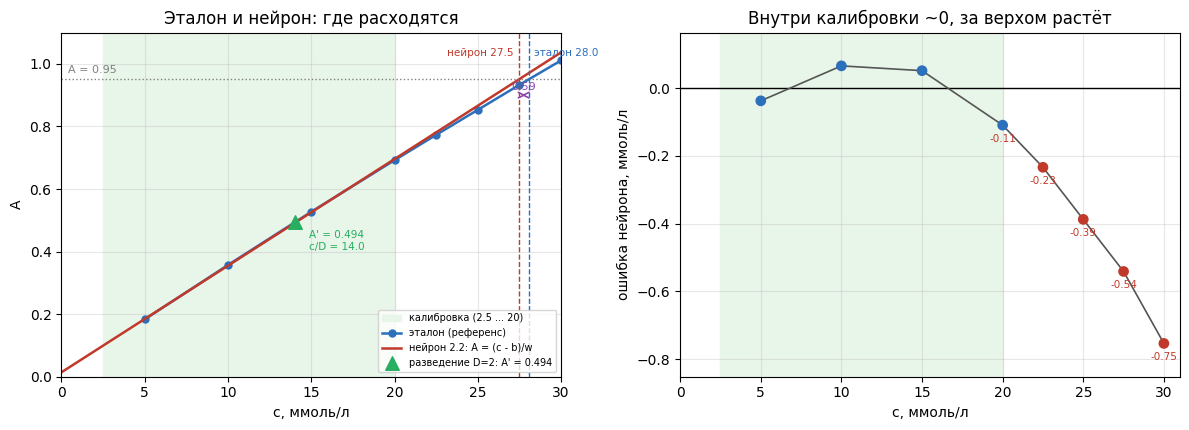

In [24]:
# 3.4* — эталон: истина, экстраполяция, разведение
c_ref = [5, 10, 15, 20, 22.5, 25, 27.5, 30]
A_ref = [0.183, 0.357, 0.527, 0.692, 0.773, 0.853, 0.933, 1.011]

def interp(x, xs, ys):
    for i in range(len(xs) - 1):
        if xs[i] <= x <= xs[i + 1]:
            t = (x - xs[i]) / (xs[i + 1] - xs[i])
            return ys[i] + t * (ys[i + 1] - ys[i])
    return None

def A_neuron(c):
    return (c - b_gd2) / w_gd2

def c_neuron(A):
    return w_gd2 * A + b_gd2

A_target = 0.950
c_true = interp(A_target, A_ref, c_ref)
c_extra = c_neuron(A_target)

print(f"Истина по эталону при A = {A_target}: c = {c_true:.2f} ммоль/л")
print(f"Экстраполяция нейрона 2.2:        c = {c_extra:.2f} ммоль/л")
print(f"Ошибка экстраполяции:             {c_extra - c_true:+.2f} ммоль/л "
      f"({(c_extra - c_true) / c_true * 100:+.1f}%)")

# --- (б) развести и вернуть ---
D_dil = 2
c_half = c_true / D_dil
A_dil = interp(c_half, c_ref, A_ref)
c_half_hat = c_neuron(A_dil)
c_back = D_dil * c_half_hat

print(f"\n(б) разведение D = {D_dil}:")
print(f"    половинная концентрация c/D = {c_half:.2f} ммоль/л")
print(f"    по эталону A' = {A_dil:.4f}")
print(f"    нейрон на A': c' = {c_half_hat:.3f} ммоль/л")
print(f"    возврат: c = D * c' = {c_back:.3f} ммоль/л")
print(f"    ошибка: {c_back - c_true:+.3f} ммоль/л ({(c_back - c_true) / c_true * 100:+.2f}%)")

# --- (в) сравнение ---
e_extra = c_extra - c_true
e_dil = c_back - c_true

print("\n(в) сравнение ошибок:")
print(f"    экстраполяция: {c_extra:.2f} ммоль/л, ошибка {e_extra:+.2f} "
      f"({abs(e_extra) / c_true * 100:.1f}%)")
print(f"    разведение:    {c_back:.2f} ммоль/л, ошибка {e_dil:+.2f} "
      f"({abs(e_dil) / c_true * 100:.1f}%)")
print(f"    разведение точнее в {abs(e_extra) / abs(e_dil):.1f} раза")

c_grid = [30 * i / 300 for i in range(301)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

# --- левая панель: эталон и нейрон ---
ax1.axvspan(2.5, 20, color='#e8f5e9', zorder=0, label='калибровка (2.5 ... 20)')
ax1.plot(c_ref, A_ref, 'o-', color='#2c6fbb', lw=1.8, ms=5, label='эталон (референс)')
ax1.plot(c_grid, [A_neuron(c) for c in c_grid], '-', color='#c0392b', lw=1.8,
         label='нейрон 2.2: A = (c - b)/w')
ax1.scatter([c_half], [A_dil], marker='^', s=95, color='#27ae60', zorder=5,
            label=f"разведение D={D_dil}: A' = {A_dil:.3f}")
ax1.annotate(f"A' = {A_dil:.3f}\nc/D = {c_half:.1f}", (c_half, A_dil),
             textcoords='offset points', xytext=(10, -20), fontsize=7.5, color='#27ae60')

ax1.axhline(A_target, color='gray', ls=':', lw=1)
ax1.text(0.4, A_target + 0.02, f'A = {A_target}', fontsize=8, color='gray')
ax1.axvline(c_true, color='#2c6fbb', ls='--', lw=1)
ax1.axvline(c_extra, color='#c0392b', ls='--', lw=1)
ax1.annotate('', xy=(c_true, 0.90), xytext=(c_extra, 0.90),
             arrowprops=dict(arrowstyle='<->', color='#8e44ad', lw=1.2))
ax1.text((c_true + c_extra) / 2, 0.915, f'{c_true - c_extra:.2f}',
         ha='center', fontsize=8, color='#8e44ad')
ax1.text(c_extra - 0.3, 1.02, f'нейрон {c_extra:.1f}', ha='right', va='bottom',
         fontsize=7.5, color='#c0392b')
ax1.text(c_true + 0.3, 1.02, f'эталон {c_true:.1f}', ha='left', va='bottom',
         fontsize=7.5, color='#2c6fbb')

ax1.set_xlim(0, 30)
ax1.set_ylim(0, 1.1)
ax1.set_xlabel('c, ммоль/л')
ax1.set_ylabel('A')
ax1.set_title('Эталон и нейрон: где расходятся')
ax1.grid(alpha=0.3)
ax1.legend(fontsize=7, loc='lower right')

# --- правая панель: ошибка нейрона в единицах c ---
err_c = [c_neuron(a) - c for c, a in zip(c_ref, A_ref)]
colors = ['#2c6fbb' if c <= 20 else '#c0392b' for c in c_ref]

ax2.axvspan(2.5, 20, color='#e8f5e9', zorder=0)
ax2.axhline(0, color='black', lw=1)
ax2.plot(c_ref, err_c, '-', color='#555', lw=1.2, zorder=2)
ax2.scatter(c_ref, err_c, c=colors, s=45, zorder=3)
ax2.set_xlim(0, 31)
ax2.set_xlabel('c, ммоль/л')
ax2.set_ylabel('ошибка нейрона, ммоль/л')
ax2.set_title('Внутри калибровки ~0, за верхом растёт')
ax2.grid(alpha=0.3)
ax2.margins(y=0.12)

for c, e in zip(c_ref, err_c):
    if c >= 20:
        ax2.annotate(f'{e:+.2f}', (c, e), textcoords='offset points',
                     xytext=(0, -12), ha='center', fontsize=7.5, color='#c0392b')

plt.tight_layout()
plt.show()


**Ответ 3.4* (что покупает разведение):**
1. Внутри диапазона 2.5 - 20 прямая нейрона и реальная кривая эталона почти совпадают. Расхождение начинается сразу за верхним калибратором 

2. (а) Экстраполяция: При А = 0.95 нейрон предсказал с = 27.46 ммоль/л. Ошибка -2.1%

3. (б) Разведение: Предсказание разведенной пробы с = 14.077 ммоль/л, при умножении на 2 с = 28.154 ммоль/л. Ошибка +0.39%

4.  Разведение оказалось в 5.4 раза точнее экстраполяции. Оно точнее, потому что возвращает измерение в зону, где прямая и кривая практически совпадают. Но оно всё же не идеально, потому что сам нейрон 2.2 обучен на изношенном приборе, плюс добавляется погрешность пипетки 

Итоговый вывод: Разведение покупает не новый способ счёта, а возвращение измерения в зону, где калибровка проверена, а линейность гарантирована.

### 3.5**. Погрешности разведения

Пипетка даёт объём с относительной погрешностью $\pm 2\%$; прибор пишет $A$ с абсолютной $\pm 0.002$.

- **(а)** разведение $1+1$ — две пипетки (проба и вода). Какова относительная погрешность фактора $D$ — и ответа пробы?
- **(б)** разведение $1+3$: воды можно отмерить тремя отдельными порциями той же пипеткой — или одной мерной колбой сразу на четыре объёма. Сравни относительную погрешность $D$ в двух вариантах.
- **(в)** погрешность прибора $\pm 0.002$ по $A$ превращается в погрешность по $c$ величиной $w \cdot 0.002$. Куда она входит в ответ $\hat c = D(w A' + b)$ — и при каком $D$ её вклад в **исходную** пробу больше: $D = 2$ или $D = 5$?

Собери суммарную оценку погрешности ответа для $D = 2$ и $D = 5$ (сложить относительные — достаточно) и реши: какое разведение ты выписала бы в регламент для проб, вылетающих за верх шкалы?

In [25]:
# 3.5** — суммарная погрешность ответа для D=2 и D=5

eps_pip = 0.02        # 2% — относительная погрешность пипетки
delta_A = 0.002       # абсолютная погрешность A
c_target = c_true     # 28.04 ммоль/л — истина из 3.4*

def rel_D(r, eps_w, eps_s=eps_pip):
    # D = 1 + r, r = V_water / V_sample; объёмы независимы
    return r / (1 + r) * (eps_w ** 2 + eps_s ** 2) ** 0.5

print("(а) 1+1, две разные пипетки:")
eD_2 = rel_D(1, eps_pip)
print(f"    δD/D = {eD_2 * 100:.2f}%  — и та же {eD_2 * 100:.2f}% для ответа пробы (фактор)")

print("\n(б) 1+3, три части воды:")
eD_3_sys = rel_D(3, eps_pip)                    # та же пипетка, систематическая ошибка
eD_3_rnd = rel_D(3, eps_pip / 3 ** 0.5)         # три независимые порции, случайные ошибки усредняются
eD_flask = (0.02 ** 2 + eps_pip ** 2) ** 0.5    # колба с той же относительной 2%
eD_flask_A = (0.002 ** 2 + eps_pip ** 2) ** 0.5 # колба класса А (~0.2%)
print(f"    три порции, систематическая: δD/D = {eD_3_sys * 100:.2f}%")
print(f"    три порции, независимые:     δD/D = {eD_3_rnd * 100:.2f}%")
print(f"    одна колба 2%:               δD/D = {eD_flask * 100:.2f}%")
print(f"    одна колба класса А (0.2%):  δD/D = {eD_flask_A * 100:.2f}%")

print("\n(в) прибор ±0.002 по A:")
for D in (2, 5):
    dc = D * w_gd2 * delta_A
    print(f"    D={D}: δc = D·w·δA = {dc:.3f} ммоль/л, это {dc / c_target * 100:.2f}%")

print("\nСуммарно (объём + прибор, в квадратуре):")
for D in (2, 5):
    eD = rel_D(D - 1, eps_pip)
    dc_rel = D * w_gd2 * delta_A / c_target
    total = (eD ** 2 + dc_rel ** 2) ** 0.5
    print(f"    D={D}: объём {eD * 100:.2f}% ⊕ прибор {dc_rel * 100:.2f}% "
          f"-> {total * 100:.2f}%")


(а) 1+1, две разные пипетки:
    δD/D = 1.41%  — и та же 1.41% для ответа пробы (фактор)

(б) 1+3, три части воды:
    три порции, систематическая: δD/D = 2.12%
    три порции, независимые:     δD/D = 1.73%
    одна колба 2%:               δD/D = 2.83%
    одна колба класса А (0.2%):  δD/D = 2.01%

(в) прибор ±0.002 по A:
    D=2: δc = D·w·δA = 0.117 ммоль/л, это 0.42%
    D=5: δc = D·w·δA = 0.293 ммоль/л, это 1.05%

Суммарно (объём + прибор, в квадратуре):
    D=2: объём 1.41% ⊕ прибор 0.42% -> 1.47%
    D=5: объём 2.26% ⊕ прибор 1.05% -> 2.49%


**Ответ 3.5 (регламентное разведение и его цена).**

(а) 1+1 (D=2): два независимых пипетирования дают погрешность фактора около 1.4%, и ровно столько же входит в ответ

(б) 1+3 (D=4): три порции воды накапливают ошибку (1.7–2.1% в зависимости от того, систематическая она или независимая). Мерная колба класса А даёт 2%, что сопоставимо с тремя порциями, но проще в исполнении.

(в) Шум по A умножается на D в ответе. При D=2 это 0.42%, при D=5 - 1.05%. Чем сильнее разведение, тем сильнее шум влияет на итог. 

Суммарно (в квадратуре): D=2 даёт 1.47%, D=5 — 2.49%.
В регламент я бы выписала D=2. При данном значении минимальное накопление ошибок. 

## Блок 4*. Генератор модельного мира *(numpy разрешён, но не обязателен)*

Все данные первой части были чьим-то решением — чьи-то «настоящие» $k$, $A_0$ и шум. Сделаем этот мир сами: тогда «правда» известна, и любую оценку можно сверить с ней — роскошь, которой нет в реальной лаборатории.

### 4.1*. Генератор и seed

Истинные параметры возьми из своей 4.12*: $k = 0.0362$, $A_0 = 0.00435$. Шум прибора — по плотности: $\sigma_A = 0.002$ (в пересчёте на концентрацию это $\pm 0.05$ ммоль/л — согласуй с остатками 4.8).

Напиши функцию `generate_A(c_list, sigma, seed)`: для каждой концентрации честная $A = A_0 + k\,c$ плюс нормальный шум (`random.gauss`). Сгенерируй свой калибровочный набор (те же пять $c$), обучи нейрон, сверь $w$ с $27.788$.

Два прогона с одним `seed` — совпали? С разными — насколько разошлись $w$? Что именно фиксирует seed и почему без него эксперимент нельзя повторить?

один seed = 1: наборы совпали = True
A = [0.0974, 0.1882, 0.3665, 0.5458, 0.7262]
по этому набору: w = 27.8654, b = -0.2234
первая часть:    w = 27.788, b = -0.121

200 seed: w от 27.294 до 27.936
среднее 27.631, стандартное отклонение 0.110
1/k = 27.624 — центр; 27.788 отстоит на 1.4 sigma


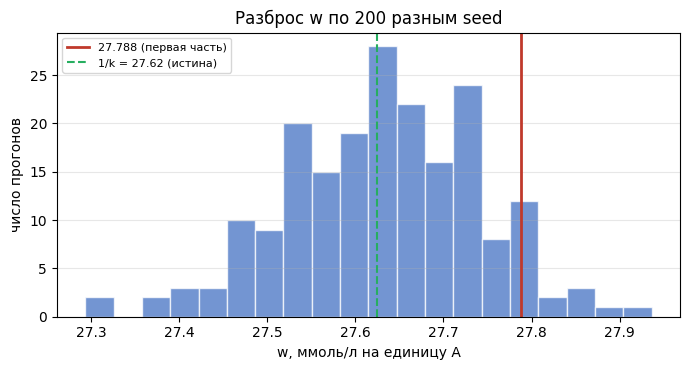

In [26]:
# 4.1* — генератор калибраторов, seed, разброс w

k_true = 0.0362        # истинные параметры из 4.12*
A0_true = 0.00435
sigma_A = 0.002        # шум прибора по оптической плотности

c_cal = [2.5, 5.0, 10.0, 15.0, 20.0]

def generate_A(c_list, sigma, seed):
    rng = random.Random(seed)      # свой генератор, глобальный random не трогаем
    return [A0_true + k_true * c + rng.gauss(0, sigma) for c in c_list]

def fit_wb(c_list, A_list):
    # тот же МНК, что в 1.1 — предел спуска из 4.5
    n = len(c_list)
    sA  = sum(A_list)
    sA2 = sum(a * a for a in A_list)
    sc  = sum(c_list)
    sAc = sum(A_list[i] * c_list[i] for i in range(n))
    D = n * sA2 - sA * sA
    return (n * sAc - sA * sc) / D, (sA2 * sc - sA * sAc) / D

# --- один seed: повторяемость ---
A_a = generate_A(c_cal, sigma_A, seed=1)
A_b = generate_A(c_cal, sigma_A, seed=1)
print(f"один seed = 1: наборы совпали = {A_a == A_b}")
print("A =", [round(a, 4) for a in A_a])

w1, b1 = fit_wb(c_cal, A_a)
print(f"по этому набору: w = {w1:.4f}, b = {b1:.4f}")
print("первая часть:    w = 27.788, b = -0.121\n")

# --- разные seed: разброс w ---
ws = []
for seed in range(200):
    A_s = generate_A(c_cal, sigma_A, seed=seed)
    ws.append(fit_wb(c_cal, A_s)[0])

print(f"200 seed: w от {min(ws):.3f} до {max(ws):.3f}")
print(f"среднее {statistics.mean(ws):.3f}, стандартное отклонение {statistics.pstdev(ws):.3f}")
print(f"1/k = {1 / k_true:.3f} — центр; 27.788 отстоит на "
      f"{(27.788 - statistics.mean(ws)) / statistics.pstdev(ws):.1f} sigma")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(ws, bins=20, color='#4472c4', alpha=0.75, edgecolor='white')
ax.axvline(27.788, color='#c0392b', lw=2, label='27.788 (первая часть)')
ax.axvline(1 / k_true, color='#27ae60', lw=1.5, ls='--', label=f'1/k = {1 / k_true:.2f} (истина)')
ax.set_xlabel('w, ммоль/л на единицу A')
ax.set_ylabel('число прогонов')
ax.set_title('Разброс w по 200 разным seed')
ax.grid(axis='y', alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Ответ 4.1* (что фиксирует seed; откуда разброс).**

Одинаковый seed даёт идентичные данные и веса, с разным seed w варьируется в пределах + - 0.11 вокруг истины (1/k=27.624). Одинаковый seed делает эксперимент воспроизводимым. Seed фиксирует начальное состояние генератора псевдослучайных чисел, то есть  при повторном запуске с тем же seed последовательность будет такой же. Без seed при каждом запуске шум будет иная реализация шума. 

### 4.2*. Сатурация

Добавь в генератор кривизну — ту самую, с которой столкнулась в 2.2:

$$A(c) = A_0 + \frac{k\,c}{1 + c/380}.$$

Сгенерируй калибраторы (без шума, те же $c$) и сравни с таблицей из 2.2 — объясняет ли эта модель мира её плотности $[0.095,\ 0.185,\ 0.360,\ 0.527,\ 0.692]$? Построй эту кривую поверх эталонной таблицы из 3.4* — сколько в них разных приборов?

Параметр $380$ — это концентрация, на которой чувствительность падает вдвое. Увеличь его до $2000$ («почти новый прибор») и покажи обе кривые: где они расходятся и что тогда останется в остатках калибровки?

c:        [2.5, 5.0, 10.0, 15.0, 20.0]
S=380:    [0.0943, 0.183, 0.3571, 0.5267, 0.6922]
таб. 2.2: [0.095, 0.185, 0.36, 0.527, 0.692]
разница:  [0.0007, 0.002, 0.0029, 0.0003, -0.0002]
макс |разница| = 0.0029 — при sigma_A = 0.002 это шум

S= 380: w = 29.254, b = -0.3426, max|r| = 0.103 ммоль/л
S=2000: w = 27.933, b = -0.1629, max|r| = 0.020 ммоль/л

шум в единицах c: w·sigma_A = 0.055 ммоль/л


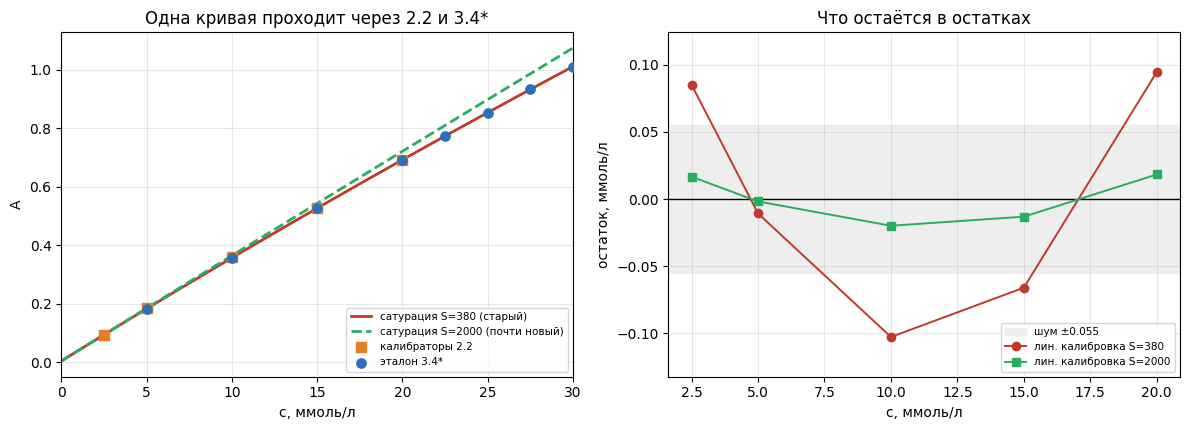

In [27]:
# 4.2* — сатурационная модель против таблиц 2.2 и 3.4*

def A_sat(c, S, k=k_true, A0=A0_true):
    return A0 + k * c / (1 + c / S)

A_22 = [0.095, 0.185, 0.360, 0.527, 0.692]          # калибраторы из 2.2
c_ref = [5, 10, 15, 20, 22.5, 25, 27.5, 30]         # эталон из 3.4*
A_ref = [0.183, 0.357, 0.527, 0.692, 0.773, 0.853, 0.933, 1.011]

A_380 = [A_sat(x, 380) for x in c_cal]
A_2000 = [A_sat(x, 2000) for x in c_cal]

print("c:       ", c_cal)
print("S=380:   ", [round(a, 4) for a in A_380])
print("таб. 2.2:", A_22)
print("разница: ", [round(A_22[i] - A_380[i], 4) for i in range(5)])
print(f"макс |разница| = {max(abs(A_22[i] - A_380[i]) for i in range(5)):.4f} "
      f"— при sigma_A = {sigma_A} это шум\n")

def fit_wb(cs, As):
    n = len(cs)
    sA = sum(As); sA2 = sum(a * a for a in As); sc = sum(cs)
    sAc = sum(As[i] * cs[i] for i in range(n))
    D = n * sA2 - sA * sA
    return (n * sAc - sA * sc) / D, (sA2 * sc - sA * sAc) / D

res = {}
for S, A_vals in [(380, A_380), (2000, A_2000)]:
    w, b = fit_wb(c_cal, A_vals)
    r = [c_cal[i] - (w * A_vals[i] + b) for i in range(5)]
    res[S] = r
    print(f"S={S:>4}: w = {w:.3f}, b = {b:+.4f}, max|r| = {max(abs(x) for x in r):.3f} ммоль/л")

sigma_c = sigma_A / k_true  # ≈0.055 ммоль/л — шум в единицах c
print(f"\nшум в единицах c: w·sigma_A = {sigma_c:.3f} ммоль/л")

c_grid = [30 * i / 200 for i in range(201)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

ax1.plot(c_grid, [A_sat(x, 380) for x in c_grid], '-', color='#c0392b', lw=2,
         label='сатурация S=380 (старый)')
ax1.plot(c_grid, [A_sat(x, 2000) for x in c_grid], '--', color='#27ae60', lw=2,
         label='сатурация S=2000 (почти новый)')
ax1.scatter(c_cal, A_22, marker='s', s=55, color='#e67e22', zorder=4, label='калибраторы 2.2')
ax1.scatter(c_ref, A_ref, s=45, color='#2c6fbb', zorder=4, label='эталон 3.4*')
ax1.set_xlim(0, 30)
ax1.set_xlabel('c, ммоль/л')
ax1.set_ylabel('A')
ax1.set_title('Одна кривая проходит через 2.2 и 3.4*')
ax1.grid(alpha=0.3)
ax1.legend(fontsize=7.5, loc='lower right')

ax2.axhspan(-sigma_c, sigma_c, color='#eeeeee', zorder=0, label=f'шум ±{sigma_c:.3f}')
ax2.axhline(0, color='black', lw=1)
ax2.plot(c_cal, res[380], 'o-', color='#c0392b', lw=1.4, label='лин. калибровка S=380')
ax2.plot(c_cal, res[2000], 's-', color='#27ae60', lw=1.4, label='лин. калибровка S=2000')
ax2.set_xlabel('c, ммоль/л')
ax2.set_ylabel('остаток, ммоль/л')
ax2.set_title('Что остаётся в остатках')
ax2.grid(alpha=0.3)
ax2.margins(y=0.15)
ax2.legend(fontsize=7.5, loc='lower right')

plt.tight_layout()
plt.show()


**Ответ 4.2* (одна ли причина у 2.2 и 3.4*).**
 На новом приборе кривая становится почти линейной в рабочем диапазоне, но всё равно отходит от калибровки. Если обучить линейный нейрон на данных нового прибора(S=2000), остатки будут иметь ту же форму что и в пункте 2.2 (правый график, зелёная линия), но их амплитуда меньше, чем у старого прибора. Модель не может описать данные идеально, но величина остатков падает ниже шума, ошибка становится допустимой.

Причина у 2.2 и 3.4* одна и та же  - отклонение от линейного закона Бера. Если S - это концентрация, при которой чувствительность падает вдвое, то чем меньше S, тем раньше прибор перестаёт быть линейным. У старого прибора нелинейность грубая модель(S=380) не может описать данные, у нового слабее(S=2000) и укладывается в границы значений шума 


## Блок 5*. Переобучение в миниатюре *(нужен генератор из 4*)*)

Классическое переобучение — когда сеть с миллионами весов запоминает шум, — одному нейрону недоступно: модель слишком слаба. Но сам механизм — подгонка под шум при малом числе точек — показывается в чистом виде.

### 5.1*. Две точки: $S = 0$ и что из этого вышло

Генератор из 4.1* с **завышенным** шумом $\sigma_A = 0.018$ (это $\approx 0.5$ ммоль/л — в десять раз больше настоящего; так эффект виден на малой выборке). Возьми первые **два** калибратора и обучи прямую по ним. $S = 0$? Идеальная калибровка?

Теперь контроль: $A = 0.235$, приписано $6.25$, допуск $\pm 10\%$. В допуске? Повтори 200 раз с разными seed: в какой доле прогонов «идеальная» калибровка проваливает контроль?

Что в этом случае запомнила прямая — закон или реализацию шума? Вернись к вопросу 2.4.3 первой части («почему $S$ в минимуме — не ноль, и почему это нормально») и переформулируй его вторую половину: когда $S = 0$ — это не везение, а диагноз?

две точки: c = [2.5, 5.0]
S в каждом прогоне: max = 7.50e-27 — ноль с точностью до машинной
ответ по контролю: от 5.07 до 10.52, медиана 6.29
допуск [5.625, 6.875]: провалили 70 из 200 = 35% (ниже 21, выше 49)


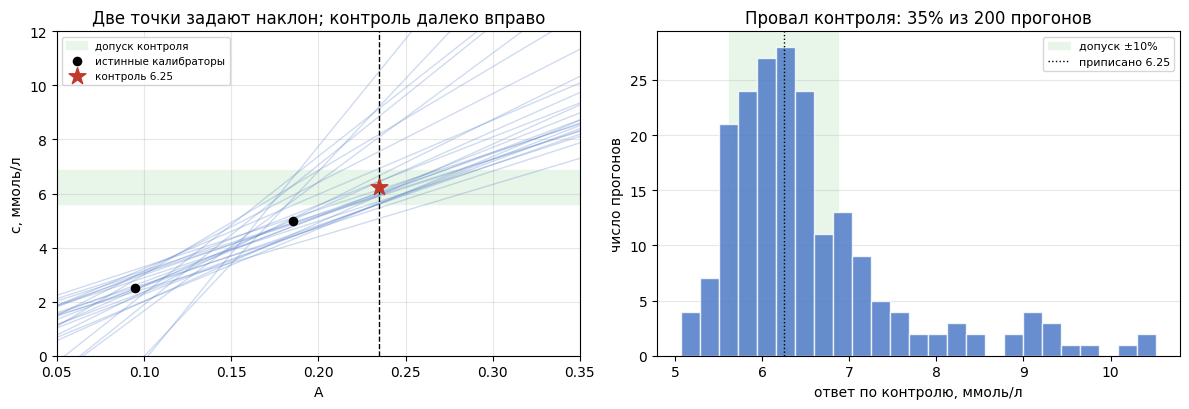

In [28]:
# 5.1* — две точки, S=0, 200 прогонов, доля провалов контроля

sigma_big = 0.018
c_two = c_cal[:2]                    # [2.5, 5.0]
N_RUNS = 200
C_CTRL, A_CTRL = 6.25, 0.235
tol = 0.10
lo, hi = C_CTRL * (1 - tol), C_CTRL * (1 + tol)

preds = []
S_list = []
lines = []

for seed in range(N_RUNS):
    A_s = generate_A(c_two, sigma_big, seed)
    w, b = fit_wb(c_two, A_s)
    r = [c_two[i] - (w * A_s[i] + b) for i in range(2)]
    S_list.append(sum(x * x for x in r))
    preds.append(w * A_CTRL + b)
    lines.append((w, b))

n_low = sum(1 for p in preds if p < lo)
n_high = sum(1 for p in preds if p > hi)
n_fail = n_low + n_high
share = n_fail / N_RUNS * 100

print(f"две точки: c = {c_two}")
print(f"S в каждом прогоне: max = {max(S_list):.2e} — ноль с точностью до машинной")
print(f"ответ по контролю: от {min(preds):.2f} до {max(preds):.2f}, "
      f"медиана {statistics.median(preds):.2f}")
print(f"допуск [{lo:.3f}, {hi:.3f}]: провалили {n_fail} из {N_RUNS} = {share:.0f}% "
      f"(ниже {n_low}, выше {n_high})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

# --- слева: две точки задают наклон, контроль далеко вправо ---
A_grid = [0.05 + 0.30 * i / 200 for i in range(201)]
for w, b in lines[:25]:
    ax1.plot(A_grid, [w * a + b for a in A_grid], color='#4472c4', alpha=0.25, lw=1)

ax1.axhspan(lo, hi, color='#e8f5e9', zorder=0, label='допуск контроля')
ax1.axvline(A_CTRL, color='black', ls='--', lw=1)
ax1.scatter([A0_true + k_true * 2.5, A0_true + k_true * 5], [2.5, 5],
            color='black', zorder=6, s=35, label='истинные калибраторы')
ax1.scatter([A_CTRL], [C_CTRL], marker='*', s=160, color='#c0392b', zorder=6,
            label='контроль 6.25')
ax1.set_xlim(0.05, 0.35)
ax1.set_ylim(0, 12)
ax1.set_xlabel('A')
ax1.set_ylabel('c, ммоль/л')
ax1.set_title('Две точки задают наклон; контроль далеко вправо')
ax1.grid(alpha=0.3)
ax1.legend(fontsize=7.5, loc='upper left')

# --- справа: распределение ответов по контролю ---
ax2.axvspan(lo, hi, color='#e8f5e9', zorder=0, label='допуск ±10%')
ax2.hist(preds, bins=25, color='#4472c4', alpha=0.8, edgecolor='white', zorder=2)
ax2.axvline(C_CTRL, color='black', ls=':', lw=1, label='приписано 6.25')
ax2.set_xlabel('ответ по контролю, ммоль/л')
ax2.set_ylabel('число прогонов')
ax2.set_title(f'Провал контроля: {share:.0f}% из {N_RUNS} прогонов')
ax2.grid(axis='y', alpha=0.3)
ax2.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()


**Ответ 5.1* (S=0: когда успех, а когда диагноз).** В данном случае точки две и два подбираемых параметра (w, b), а значит что прямая пройдет точно через это точки, потому что прямая обязана пройти через любые две точки на плоскости. Поскольку точек мало, любое отклонение измерений значительно меняет наклон прямой. При этом контроль находится за пределами калибровочного диапазона, где линейная зависимость не гарантирована. Ненулевой минимум S в калибровке нормален, потому что отражает неустранимый шум прибора, нулевая ошибка же означает, что модель подстроилась под случайные отклонения конкретной пары калибраторов. 

### 5.2*. Кривые обучения по размеру выборки

Для $n$ из $\{2, 3, 4, 5, 8, 12, 20\}$ (генератор 4.1*, **настоящий** шум; концентрации равномерно по диапазону 2.5–20) усредни по 30 реализациям:

- ошибку на **обучающих** точках (средний квадратичный остаток);
- ошибку против **истинной прямой** $A_0 + k c$ на той же сетке $c$ — она играет честный контроль: правду мы теперь знаем.

Построй обе кривые против $n$. Одна растёт, другая падает — объясни обе. Почему «больше данных — хуже на обучении» не противоречит «больше данных — лучше модель»?

n= 2: обучение 0.0000, против истины 0.0554
n= 3: обучение 0.0304, против истины 0.0410
n= 4: обучение 0.0361, против истины 0.0382
n= 5: обучение 0.0406, против истины 0.0356
n= 8: обучение 0.0473, против истины 0.0262
n=12: обучение 0.0497, против истины 0.0192
n=20: обучение 0.0533, против истины 0.0162


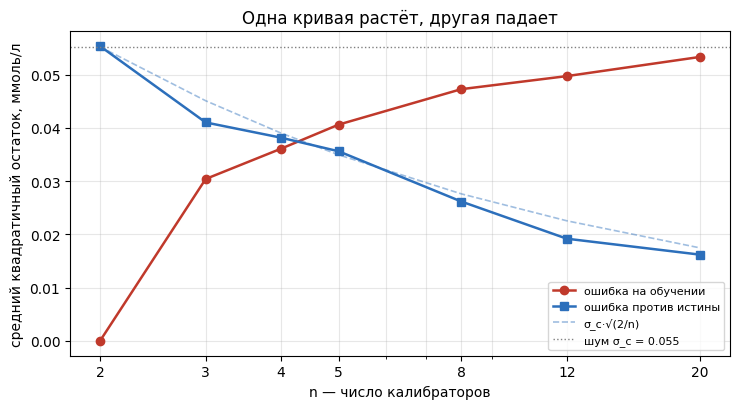

In [29]:
# 5.2* — learning curves по n: train против истины

n_list = [2, 3, 4, 5, 8, 12, 20]
N_RUNS = 30
sigma_c = sigma_A / k_true          # 0.055 — шум в единицах c

def c_grid(n):
    return [2.5 + (20 - 2.5) * i / (n - 1) for i in range(n)]

train_err = []
truth_err = []

for n in n_list:
    c_n = c_grid(n)
    tr, te = [], []
    for seed in range(N_RUNS):
        A_n = generate_A(c_n, sigma_A, seed)
        w, b = fit_wb(c_n, A_n)

        rms_train = math.sqrt(sum((c_n[i] - (w * A_n[i] + b)) ** 2 for i in range(n)) / n)
        tr.append(rms_train)

        A_true = [A0_true + k_true * x for x in c_n]
        rms_truth = math.sqrt(sum((c_n[i] - (w * A_true[i] + b)) ** 2 for i in range(n)) / n)
        te.append(rms_truth)

    train_err.append(statistics.mean(tr))
    truth_err.append(statistics.mean(te))
    print(f"n={n:>2}: обучение {train_err[-1]:.4f}, против истины {truth_err[-1]:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(n_list, train_err, 'o-', color='#c0392b', lw=1.8, label='ошибка на обучении')
ax.plot(n_list, truth_err, 's-', color='#2c6fbb', lw=1.8, label='ошибка против истины')
ax.plot(n_list, [sigma_c * math.sqrt(2 / n) for n in n_list], '--',
        color='#2c6fbb', alpha=0.45, lw=1.2, label='σ_c·√(2/n)')
ax.axhline(sigma_c, color='gray', ls=':', lw=1, label=f'шум σ_c = {sigma_c:.3f}')
ax.set_xscale('log')
ax.set_xticks(n_list)
ax.set_xticklabels([str(n) for n in n_list])
ax.set_xlabel('n — число калибраторов')
ax.set_ylabel('средний квадратичный остаток, ммоль/л')
ax.set_title('Одна кривая растёт, другая падает')
ax.grid(alpha=0.3, which='both')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Ответ 5.2* (две кривые и их встречное движение).** Красная кривая показывает величину ошибки в зависимости от числа калибраторов. В пункте 5.1 мы видели ситуацию, где при двух калибраторах S=0, однако модель обладала слабой предсказательной способностью, т.к. подстраивалась под любой шум. Здесь при увеличении количества калибраторов увеличивается и ошибка обучения, кривая не может пройти ровно через все точки. 

Синяя кривая, наоборот, падает с ростом n. Чем больше калибраторов, тем точнее нейрон оценивает параметры w и b, и тем ближе его прямая к истинной прямой A_i = A0 + kc, следовательно, величина ошибки против истины снижается. 

### 5.3*. Разброс весов

200 реализаций шума при $n = 5$ и при $n = 50$: гистограммы $w$ (и $b$ рядом). Во сколько раз разброс при 50 точках меньше — и сколько обещает теория ($\sim 1/\sqrt{n}$)?

Сравни с оврагом из 4.12*: разброс $w$ и $b$ — вдоль какого направления чаши он шире? Свяжи: плохо обусловленная задача = шаткие веса = разброс между реализациями. Это и есть дисперсия оценки; а систематическое отставание прямой от кривых данных из 2.2 — смещение модели. Теперь у тебя оба слова — на своих картинах.

n= 5: w = 27.6298 ± 0.1138, b = -0.1240 ± 0.0525
n=50: w = 27.6261 ± 0.0403, b = -0.1211 ± 0.0174

разброс упал: w в 2.83 раза, b в 3.02 раза; теория sqrt(50/5) = 3.16
корреляция w и b при n=5: -0.878
гессиан: lambda_min = 0.213, lambda_max = 5.885, cond = 27.6
направление оврага: dw : db = 1 : -0.430


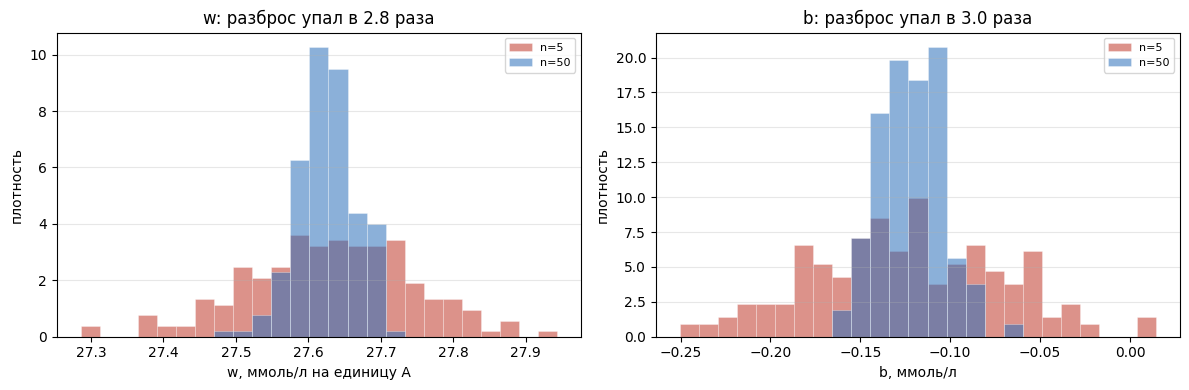

In [30]:
# 5.3* — гистограммы w и b при n=5 и n=50

N_RUNS = 200
W = {5: [], 50: []}
B = {5: [], 50: []}

for n in (5, 50):
    c_n = c_grid(n)
    for seed in range(N_RUNS):
        A_n = generate_A(c_n, sigma_A, seed)
        w, b = fit_wb(c_n, A_n)
        W[n].append(w)
        B[n].append(b)

for n in (5, 50):
    print(f"n={n:>2}: w = {statistics.mean(W[n]):.4f} ± {statistics.pstdev(W[n]):.4f}, "
          f"b = {statistics.mean(B[n]):+.4f} ± {statistics.pstdev(B[n]):.4f}")

ratio_w = statistics.pstdev(W[5]) / statistics.pstdev(W[50])
ratio_b = statistics.pstdev(B[5]) / statistics.pstdev(B[50])
print(f"\nразброс упал: w в {ratio_w:.2f} раза, b в {ratio_b:.2f} раза; "
      f"теория sqrt(50/5) = {math.sqrt(10):.2f}")

# корреляция и направление оврага при n = 5
ws, bs = W[5], B[5]
mw, mb = statistics.mean(ws), statistics.mean(bs)
cov = sum((ws[i] - mw) * (bs[i] - mb) for i in range(N_RUNS)) / N_RUNS
corr = cov / (statistics.pstdev(ws) * statistics.pstdev(bs))

c5 = c_grid(5)
A5 = [A0_true + k_true * x for x in c5]
S_A, S_A2 = sum(A5), sum(a * a for a in A5)
tr = S_A2 + 5
det = S_A2 * 5 - S_A * S_A
lam_min = (tr - math.sqrt(tr * tr - 4 * det)) / 2
lam_max = (tr + math.sqrt(tr * tr - 4 * det)) / 2
print(f"корреляция w и b при n=5: {corr:+.3f}")
print(f"гессиан: lambda_min = {lam_min:.3f}, lambda_max = {lam_max:.3f}, "
      f"cond = {lam_max / lam_min:.1f}")
print(f"направление оврага: dw : db = 1 : {(lam_min - S_A2) / S_A:+.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for n, color in [(5, '#c0392b'), (50, '#2c6fbb')]:
    ax1.hist(W[n], bins=25, range=(min(W[5]), max(W[5])), density=True,
             alpha=0.55, color=color, edgecolor='white', linewidth=0.4, label=f'n={n}')
    ax2.hist(B[n], bins=25, range=(min(B[5]), max(B[5])), density=True,
             alpha=0.55, color=color, edgecolor='white', linewidth=0.4, label=f'n={n}')

ax1.set_xlabel('w, ммоль/л на единицу A')
ax1.set_ylabel('плотность')
ax1.set_title(f'w: разброс упал в {ratio_w:.1f} раза')
ax1.grid(axis='y', alpha=0.3)
ax1.legend(fontsize=8)

ax2.set_xlabel('b, ммоль/л')
ax2.set_ylabel('плотность')
ax2.set_title(f'b: разброс упал в {ratio_b:.1f} раза')
ax2.grid(axis='y', alpha=0.3)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()


**Ответ 5.3* (дисперсия и смещение — своими словами).** Дисперсия показывает вариабельность результатов от случая к случаю, при больших количествар данных снижается так как модель при увеличении выборки меньше реагирует на шум. Смещение же показывает систематическую ошибку самой модели. 

## Блок 6*. Дообучение и забывание

Завод отгрузил новый лот реагента. Глюкоза та же, но чувствительность чуть другая — лаборатория перемеряла калибраторы, и таблица получилась новой:

| Раствор | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| $c$, ммоль/л | 2.5 | 5.0 | 10.0 | 15.0 | 20.0 |
| $A$, лот Б | 0.092 | 0.178 | 0.351 | 0.524 | 0.697 |

Старый лот дальше называется А (это таблица первой части).

### 6.1*. Новый лот

Обучи нейрон Б по новым точкам. Построй все **десять** точек на одном графике (лоты — разными маркерами) и обе прямые. Прогони нейрон А и нейрон Б по калибраторам обоих лотов: таблица остатков $2 \times 2$.

Может ли одна прямая обслужить оба лота? Что будет делать лаборатория, если оба лота в работе одновременно — а в анализатор зашит один нейрон?

нейрон А: w = 27.7884, b = -0.1207
нейрон Б: w = 28.9180, b = -0.1534
сверка лота Б: sum_A = 1.8420, sum_A2 = 0.9237, sum_Ac = 26.4300 — совпадает с ручным счётом

max|r|, ммоль/л:
             лот А    лот Б
нейрон А     0.052    0.752
нейрон Б     0.754    0.007

RMS, ммоль/л:
             лот А    лот Б
нейрон А     0.032    0.458
нейрон Б     0.478    0.005


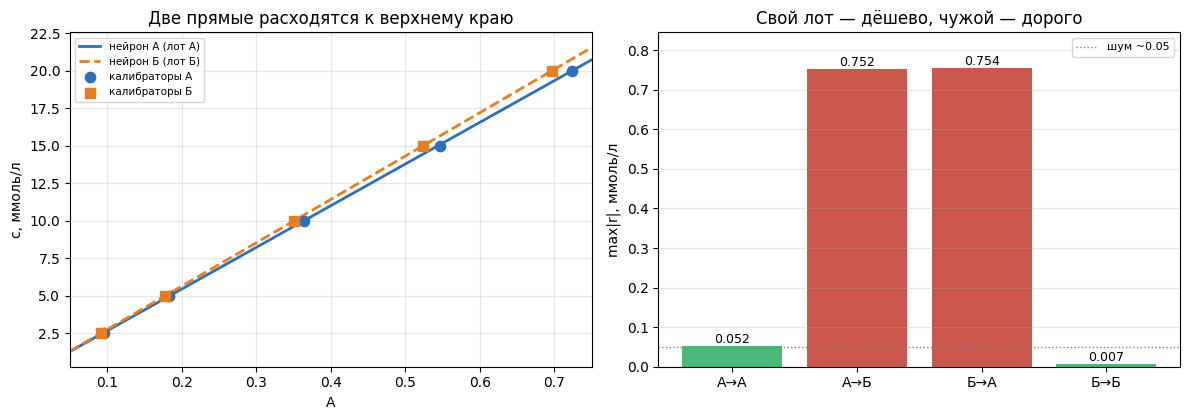

In [31]:
# 6.1* — два лота: нейрон А, нейрон Б, таблица 2x2

c_a = [2.5, 5.0, 10.0, 15.0, 20.0]
A_a = [0.095, 0.183, 0.364, 0.546, 0.723]   # лот А (первая часть)
c_b = [2.5, 5.0, 10.0, 15.0, 20.0]
A_b = [0.092, 0.178, 0.351, 0.524, 0.697]   # лот Б

w_a, b_a = fit_wb(c_a, A_a)
w_b, b_b = fit_wb(c_b, A_b)

print(f"нейрон А: w = {w_a:.4f}, b = {b_a:+.4f}")
print(f"нейрон Б: w = {w_b:.4f}, b = {b_b:+.4f}")
print(f"сверка лота Б: sum_A = {sum(A_b):.4f}, sum_A2 = {sum(a * a for a in A_b):.4f}, "
      f"sum_Ac = {sum(A_b[i] * c_b[i] for i in range(5)):.4f} — совпадает с ручным счётом\n")

def res_stats(w, b, c_lot, A_lot):
    r = [c_lot[i] - (w * A_lot[i] + b) for i in range(len(A_lot))]
    return max(abs(x) for x in r), math.sqrt(sum(x * x for x in r) / len(r))

max_aa, rms_aa = res_stats(w_a, b_a, c_a, A_a)
max_ab, rms_ab = res_stats(w_a, b_a, c_b, A_b)
max_ba, rms_ba = res_stats(w_b, b_b, c_a, A_a)
max_bb, rms_bb = res_stats(w_b, b_b, c_b, A_b)

print("max|r|, ммоль/л:")
print("             лот А    лот Б")
print(f"нейрон А   {max_aa:7.3f}  {max_ab:7.3f}")
print(f"нейрон Б   {max_ba:7.3f}  {max_bb:7.3f}")

print("\nRMS, ммоль/л:")
print("             лот А    лот Б")
print(f"нейрон А   {rms_aa:7.3f}  {rms_ab:7.3f}")
print(f"нейрон Б   {rms_ba:7.3f}  {rms_bb:7.3f}")

A_grid = [0.05 + 0.70 * i / 200 for i in range(201)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

ax1.plot(A_grid, [w_a * a + b_a for a in A_grid], '-', color='#2c6fbb', lw=2,
         label='нейрон А (лот А)')
ax1.plot(A_grid, [w_b * a + b_b for a in A_grid], '--', color='#e67e22', lw=2,
         label='нейрон Б (лот Б)')
ax1.scatter(A_a, c_a, s=55, color='#2c6fbb', zorder=4, label='калибраторы А')
ax1.scatter(A_b, c_b, s=55, marker='s', color='#e67e22', zorder=4, label='калибраторы Б')
ax1.set_xlim(0.05, 0.75)
ax1.set_xlabel('A')
ax1.set_ylabel('c, ммоль/л')
ax1.set_title('Две прямые расходятся к верхнему краю')
ax1.grid(alpha=0.3)
ax1.legend(fontsize=7.5, loc='upper left')

labels = ['А→А', 'А→Б', 'Б→А', 'Б→Б']
vals = [max_aa, max_ab, max_ba, max_bb]
colors = ['#27ae60', '#c0392b', '#c0392b', '#27ae60']
bars = ax2.bar(labels, vals, color=colors, alpha=0.85)
ax2.axhline(0.05, color='gray', ls=':', lw=1, label='шум ~0.05')
for bar, v in zip(bars, vals):
    ax2.annotate(f'{v:.3f}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 ha='center', va='bottom', fontsize=9)
ax2.set_ylabel('max|r|, ммоль/л')
ax2.set_title('Свой лот — дёшево, чужой — дорого')
ax2.grid(axis='y', alpha=0.3)
ax2.margins(y=0.12)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()


**Ответ 6.1* (ёмкость прямой на сколько лотов).** Нет, одна прямая не может обслужить два лота. Каждая прямая имеет свои уникальные коэффициенты w и b, и не может с той же точностью описать данные другого лота (ошибка выходит за допустимые пределы).

Если в лаборатории одновременно используются реагенты разных партий, то применяют следующие решения:
 1. если калибровка уже сделана предприятием-изготовителем, то используется она.
 2. если результаты на старом и новом лотах на контрольных/пациентских пробах практически идентичны, лаборатория может продолжать работать по старой калибровке.

### 6.2*. Компромисс (replay) и перенос

- **Компромисс:** обучи третий нейрон сразу по всем десяти точкам. Таблица: максимальный остаток трёх нейронов (А, Б, АБ) на каждом лоте. Кто врёт всем понемногу — и сколько это в ммоль/л против нейрона «своего» лота?
- **Дообучение:** возьми веса нейрона А и продолжай спуск по точкам лота Б ($\eta$ поменьше, например $0.05$). Сколько итераций до сходимости — против старта с $(0,0)$? Это перенос обучения в миниатюре: готовые веса — лучшая стартовая точка.
- **Забывание:** после дообучения прогони нейрон по точкам лота А. Что с ними стало? Стало ли лучше от компромисса 10 точек — вспомни таблицу выше.

Итог блока: у прямой ёмкость ровно на один лот; компромисс ошибается везде; дообучение чинит новое, забывая старое. У глубоких сетей ёмкости на порядки больше — но катастрофическое забывание у них то же самое, и лечится так же: подмешиванием старых данных (replay).

компромисс АБ: w = 28.3043, b = -0.1226

max|r|, ммоль/л:
             лот А    лот Б
нейрон А     0.052    0.752
нейрон Б     0.754    0.007
нейрон АБ    0.341    0.395

АБ против своего: на А в 6.6 раза хуже, на Б в 56 раз хуже

дообучение с (0, 0):   822 итераций -> w = 28.918027, b = -0.153401
дообучение с весов А: 673 итераций -> w = 28.918027, b = -0.153401
экономия: 149 итераций (18%)

после дообучения на лоте А: max|r| = 0.754 ммоль/л (это вес нейрона Б, лот А забыт)
компромисс АБ на лоте А:    0.341 — вдвое лучше, но в 6.6 раза хуже своего


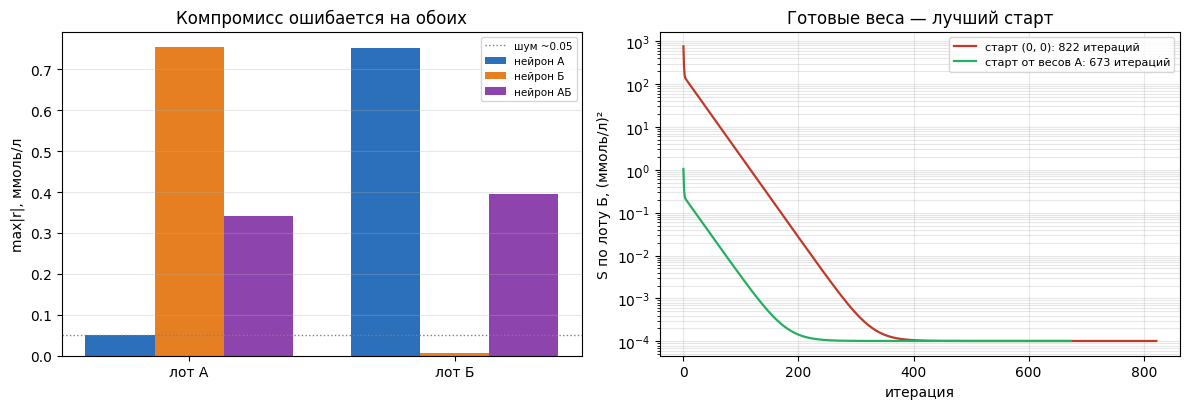

In [32]:
# 6.2* — компромисс, дообучение, забывание

# --- компромисс: третий нейрон по всем 10 точкам ---
c_all = c_a + c_b
A_all = A_a + A_b
w_ab, b_ab = fit_wb(c_all, A_all)

def max_res(w, b, c_lot, A_lot):
    return max(abs(c_lot[i] - (w * A_lot[i] + b)) for i in range(len(A_lot)))

print(f"компромисс АБ: w = {w_ab:.4f}, b = {b_ab:+.4f}\n")

print("max|r|, ммоль/л:")
print("             лот А    лот Б")
for name, w, b in [("нейрон А", w_a, b_a), ("нейрон Б", w_b, b_b), ("нейрон АБ", w_ab, b_ab)]:
    print(f"{name:<10} {max_res(w, b, c_a, A_a):7.3f}  {max_res(w, b, c_b, A_b):7.3f}")

err_ab_a = max_res(w_ab, b_ab, c_a, A_a)
err_ab_b = max_res(w_ab, b_ab, c_b, A_b)
print(f"\nАБ против своего: на А в {err_ab_a / max_res(w_a, b_a, c_a, A_a):.1f} раза хуже, "
      f"на Б в {err_ab_b / max_res(w_b, b_b, c_b, A_b):.0f} раз хуже")

# --- дообучение: спуск по лоту Б из двух стартов ---
def S_B(w, b):
    return sum((c_b[i] - (w * A_b[i] + b)) ** 2 for i in range(5))

def grad_B(w, b):
    dw = -2 * sum(A_b[i] * (c_b[i] - (w * A_b[i] + b)) for i in range(5))
    db = -2 * sum(c_b[i] - (w * A_b[i] + b) for i in range(5))
    return dw, db

def tune(w0, b0, eta=0.05, tol=1e-8, max_iter=50000):
    w, b = w0, b0
    hist = [S_B(w, b)]
    for k in range(1, max_iter + 1):
        dw, db = grad_B(w, b)
        w2, b2 = w - eta * dw, b - eta * db
        hist.append(S_B(w2, b2))
        if max(abs(w2 - w), abs(b2 - b)) < tol:
            return k, w2, b2, hist
        w, b = w2, b2
    return None, w, b, hist

k0, w0_end, b0_end, hist0 = tune(0.0, 0.0)
kA, wA_end, bA_end, histA = tune(w_a, b_a)

print(f"\nдообучение с (0, 0):   {k0} итераций -> w = {w0_end:.6f}, b = {b0_end:+.6f}")
print(f"дообучение с весов А: {kA} итераций -> w = {wA_end:.6f}, b = {bA_end:+.6f}")
print(f"экономия: {k0 - kA} итераций ({(k0 - kA) / k0 * 100:.0f}%)")

# --- забывание ---
forget = max_res(wA_end, bA_end, c_a, A_a)
print(f"\nпосле дообучения на лоте А: max|r| = {forget:.3f} ммоль/л "
      f"(это вес нейрона Б, лот А забыт)")
print(f"компромисс АБ на лоте А:    {err_ab_a:.3f} — вдвое лучше, но в "
      f"{err_ab_a / max_res(w_a, b_a, c_a, A_a):.1f} раза хуже своего")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

# --- слева: три нейрона на двух лотах ---
lots = ['лот А', 'лот Б']
vals_a = [max_res(w_a, b_a, c_a, A_a), max_res(w_a, b_a, c_b, A_b)]
vals_b = [max_res(w_b, b_b, c_a, A_a), max_res(w_b, b_b, c_b, A_b)]
vals_ab = [err_ab_a, err_ab_b]

x = range(len(lots))
wbar = 0.26
ax1.bar([i - wbar for i in x], vals_a, width=wbar, color='#2c6fbb', label='нейрон А')
ax1.bar(list(x), vals_b, width=wbar, color='#e67e22', label='нейрон Б')
ax1.bar([i + wbar for i in x], vals_ab, width=wbar, color='#8e44ad', label='нейрон АБ')
ax1.axhline(0.05, color='gray', ls=':', lw=1, label='шум ~0.05')
ax1.set_xticks(list(x))
ax1.set_xticklabels(lots)
ax1.set_ylabel('max|r|, ммоль/л')
ax1.set_title('Компромисс ошибается на обоих')
ax1.grid(axis='y', alpha=0.3)
ax1.legend(fontsize=7.5)

# --- справа: кривые обучения из двух стартов ---
ax2.semilogy(hist0, color='#c0392b', lw=1.6, label=f'старт (0, 0): {k0} итераций')
ax2.semilogy(histA, color='#27ae60', lw=1.6, label=f'старт от весов А: {kA} итераций')
ax2.set_xlabel('итерация')
ax2.set_ylabel('S по лоту Б, (ммоль/л)²')
ax2.set_title('Готовые веса — лучший старт')
ax2.grid(alpha=0.3, which='both')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()


**Ответ 6.2* (что выбирает лаборатория и почему).** Нейрон АБ (обученный на обоих лотах) врет всем по немногу (на А в 6.6 раза хуже, на Б в 56 раз хуже). Если взять веса нейрона А и дообучить его на лоте Б, сходимость наступает быстрее, чем при старте с нуля. Однако это приводит к катастрофическому забыванию: после дообучения ошибка на лоте А возвращается к 0.754 ммоль/л. Таким образом видно, что дообучение стирает старые знания. На практике лаборатория будет использовать либо отдельные калибровки для каждого лота (как в 6.1), либо подмешивание точек старого лота при калибровке нового, чтобы предотвратить забывание и сохранить работоспособность на обоих лотах.

## Блок 7*. Гигиена контроля

Контроль — это тест: материал с известным ответом, который **не участвовал в обучении**. У теста есть одно враждебное свойство: если его касаться руками, он перестаёт быть тестом.

### 7.1*. Подгонка по контролю

Продолжение 1.1. После промаха контроль дал $6.83$ — формально в допуске, но у самой границы ($6.875$). Лаборант решил «подстраховаться»: сдвинул $b$ так, чтобы контроль сел ровно на приписанные $6.25$.

Посчитай: поправку к $b$; что стало с пациентом из 1.1 ($A = 0.415$; до правки нейрон с промахом отвечал $11.81$, честный — $11.41$); что стало со **вторым** контрольным материалом (приписано $12.5$, $A = 0.457$; до правки он показывал $12.97$ при допуске до $13.75$).

Сколько ммоль/л эта правка прибавила или убавила **каждому** пациенту лаборатории — включая тех, чьи пробирки ещё не открыты? Прошёл ли второй контроль до правки и после? Почему теперь первый контроль больше ничего не проверяет? Как правильно было — вспомни, чем закончился блок 1.

In [33]:
# 7.1* — правка по контролю: кто и на сколько сдвинулся


**Ответ 7.1* (что ломает подгонка по тесту).**

### 7.2*. Сколько контролей и где они сидят

Два контрольных материала: $6.25$ (тот же, $A = 0.227$ на изношенном приборе) и новый, верхний: приписано $17.5$, на этом приборе $A = 0.610$.

Прогони оба через **нейрон из 2.2** (обучен на изношенных калибраторах): допуски $\pm 10\%$. Оба молчат?

Тогда вопрос на подумать: контроль с допуском — грубый инструмент; что он видит, а что видят остатки из 2.2? Почему один контроль в середине диапазона — мало, и как расставить два: оба в середине, оба по краям, один внизу и один наверху? Проверь свой вариант на изношенном приборе: какая расстановка раньше заметит, что наверху что-то не так (загляни в 3.4*)?

In [34]:
# 7.2* — два контроля против кривизны: где сидеть


**Ответ 7.2* (расстановка контролей и что видят остатки).**

## Блок 8*. Поиск шага *(numpy разрешён; нужны данные первой части)*

В 4.5 шаг был константой, и ты нашла его границу: $\eta^* = 2/\lambda_{\max}$. А между направлениями, которые чаша сжимает по-разному, шаг можно **искать** на каждой итерации — одномерной минимизацией вдоль направления спуска. Это наискорейший спуск, и твоё золотое сечение из блока 2 первой части становится его подпрограммой.

### 8.1*. Наискорейший спуск на рабочей чаше

Гессиан $S$ — матрица $2\times2$; её собственные числа считаются через след и определитель (Крамер ты уже писала). Для рабочей прямой должно выйти $\lambda_{\min} \approx 0.46$, $\lambda_{\max} \approx 11.5$ — проверь (заодно сверь $\eta^* = 2/\lambda_{\max}$ со своей $0.173$ из 4.5).

Сравни на одних осях:

- спуск с постоянным оптимальным шагом $\eta = 2/(\lambda_{\min} + \lambda_{\max})$;
- наискорейший: направление $-\mathrm{grad}$, шаг — золотым сечением вдоль луча.

Считай не только **итерации**, но и **вызовы $S$** (каждое сужение золотого сечения — вызов). Кто победил по вызовам — и почему на почти круглой чаше это не наискорейший?

In [35]:
# 8.1* — постоянный шаг против поиска шага: итерации и вызовы


**Ответ 8.1* (цена точного поиска на круглой чаше).**

### 8.2*. Овраг 4.12* и момент

То же на **физической** прямой ($k$, $A_0$) из 4.12* — там овраг: $\lambda_{\min} \approx 2.7$, $\lambda_{\max} \approx 1520$, $\kappa \approx 560$ (проверь). Построй траектории на линиях уровня — гребёнка знакома по сентябрю и 4.12*.

Посчитай число итераций до снижения $S$ в 100 раз: постоянный шаг $\eta_{\text{opt}}$, наискорейший, и momentum ($\beta = 0.9$, $\eta = \eta_{\text{opt}}$; формула была в твоём «Оптимизаторы 2D» октября). Таблица из трёх строк.

Вывод, к которому подводит овраг: точный поиск шага ускоряет движение **вдоль хорошего направления**, момент — чинит **плохую геометрию** чаши. Это разные лекарства, и $\kappa$ показывает, кому какое нужно. Сверься с октябрём: что из этого делал Momentum, а что AdaGrad/Adam?

In [36]:
# 8.2* — овраг: три метода, гребёнка, таблица итераций


**Ответ 8.2* (кто что лечит).**

### 8.3*. SGD и точный поиск шага

Возьми SGD из 4.11* (обновление после каждого калибратора) и попробуй добавить точный поиск шага по **одной** точке: вдоль $-\mathrm{grad}$ одной точки ищи минимум золотым сечением.

Что происходит с траекторией — и почему минимизация вдоль одной точки бессмысленна (какая «чаша» у одного калибратора и чем она отличается от чаши всех пяти)? Не забудь: на следующем калибраторе функция уже другая.

Сделай вывод одной фразой: почему большие сети живут с Adam и расписаниями шага (одно ты уже добавила в 4.11* по ревью 05.11), а не с золотым сечением. В классической оптимизации точный поиск шага жив и здоров — где граница между этими мирами?

In [37]:
# 8.3* — SGD + золотое сечение: что ломается


**Ответ 8.3* (граница применимости точного поиска).**

## Блок 9*. Мелочи, которые пригодятся

Три коротких сюжета — по одной ячейке каждый.

### 9.1*. Три старта

Спуск из $(0, 0)$, из твоей прикидки на глаз из 4.2, из случайной точки (генератор из 4.1*). Таблица: итерации до сходимости, финальные $w$, $b$. Ответы обязаны совпасть — почему (сколько чаш у квадратичной $S$)? Запиши и обратное: где этот аргумент сломается в глубоких сетях — и что тогда решает старт.

In [38]:
# 9.1* — три старта: итерации и ответ


**Ответ 9.1* (что решает старт здесь и там).**

### 9.2*. Обе кривые по итерациям

Кривая $S$ на калибраторах и ошибка на контрольном материале — по итерациям спуска, на одном графике (нормируй, чтобы было видно обе). Где плато — там ранняя остановка.

Запиши словами: почему **здесь** не может появиться картинка «ошибка на обучении падает, на контроле растёт» — и в какой задаче из этого задачника она появится (подсказка: 5.1*). Это главный симптом переобучения, и важно встретить его впервые на данных, где его нет.

In [39]:
# 9.2* — кривая обучения и кривая контроля по итерациям


**Ответ 9.2* (почему здесь train/val не разойдутся).**

### 9.3*. Нейрон всегда ответит

Прогони нейрон первой части на $A = 0.950$ (уже было), $A = -0.05$, $A = 0.000$ и $A$ с испорченной пробиркой — `float('nan')`. Что он вернул на каждом? Какой ответ физически осмыслен и почему?

Где граница доверия нейрона и кто её держит — формула или регламент? Запиши мост к диплому одним предложением: сеть сегментации тоже всегда выдаст маску — в том числе на снимке другого модалитета или разрешения; вход за пределами обучающих данных не экстраполируют, а приводят в диапазон — и разведение из блока 3 это ровно оно.

In [40]:
# 9.3* — нейрон на плохих входах


**Ответ 9.3* (кто держит границу).**

## Словарь: как это называется в нейросетях

| В задаче | В нейросетях |
|---|---|
| испорченная точка калибровки | выброс (outlier) |
| Хубер с урезанием веса | робастная оценка, весовая функция |
| $\delta$ из 1.3* | гиперпараметр — первый с физическим смыслом: «что шум, а что брак» |
| «не дошёл» / «не может» (2.1 / 2.2) | недообучение: ранняя остановка / нехватка ёмкости модели |
| две точки, $S = 0$ (5.1*) | переобучение в миниатюре: подгонка под реализацию шума |
| кривые по размеру выборки (5.2*) | learning curves |
| разброс весов между реализациями (5.3*) | дисперсия оценки (variance); отставание прямой от кривых данных — смещение (bias) |
| новый лот реагента (6*) | дообучение (fine-tuning) |
| после дообучения лот А развалился | катастрофическое забывание; лекарство — replay |
| старт дообучения от готовых весов | перенос обучения (transfer learning) |
| правка $b$ по контролю (7.1*) | утечка (data leakage): тест, под который подгоняли, — больше не тест |
| пробы за пределами калибраторов (3.4*) | вне распределения (out-of-distribution) |
| поиск шага золотым сечением (8*) | одномерный поиск шага (line search); наискорейший спуск |
| $\kappa = \lambda_{\max}/\lambda_{\min}$ | обусловленность; овраг = плохо обусловленная задача |
| $\eta(t)$, убывающая со временем | расписание шага (learning rate schedule) |
| генератор с известными $k$, $A_0$ (4*) | модельные данные, ground truth |

---

### Финальная ячейка

Три–пять предложений своими словами: что оказалось самым неожиданным во всём задачнике; что осталось непонятным — это список вопросов к следующему этапу; и что из пройденного напрямую пригодится в дипломе — назови сам(а) хотя бы одно.